# WT-MT comparison of MHC-binding predictions

Для каждого пептида percentile rank считается относительно decoy-пептидов той же длины. Затем WT и MT соединяются по исходной строке окна, и для каждого предиктора определяется, приобрела ли мутация сильное связывание. **Меньший percentile rank всегда лучше; strong binder = top 2%.**


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullLocator




In [2]:
PROJECT_DIR = (Path.home() / "Hussein").resolve()  

PREDICTIONS_DIR = PROJECT_DIR / "predictions" / "final_tables"
MUTATIONS_DIR = PROJECT_DIR / "mutation_peptides"
TPM_FILE = PROJECT_DIR / "transcript_tpm.tsv"
OUTPUT_DIR = PREDICTIONS_DIR / "wt_mt_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLES = ["ID8", "ID8_CPR"]
LENGTHS = [8, 9, 15]
TOP_PERCENT = 2.0

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

In [3]:
tpm = pd.read_csv(TPM_FILE, sep="\t", low_memory=False)

In [4]:
def read_tsv(path):
    return pd.read_csv(path, sep="\t", low_memory=False)

target_frames = []
for sample in SAMPLES:
    for length in LENGTHS:
        path = PREDICTIONS_DIR / "target" / f"{sample}.length-{length}.predictions.tsv"
        frame = read_tsv(path).copy()
        frame["sample"] = sample
        frame["length"] = length
        target_frames.append(frame)

target_predictions = pd.concat(target_frames, ignore_index=True)

decoy_frames = []
for length in LENGTHS:
    path = PREDICTIONS_DIR / "decoy" / f"DECOY.length-{length}.predictions.tsv"
    frame = read_tsv(path).copy()
    frame["length"] = length
    decoy_frames.append(frame)

decoy_predictions = pd.concat(decoy_frames, ignore_index=True)

print(f"TARGET rows: {len(target_predictions):,}")
print(f"DECOY rows:  {len(decoy_predictions):,}")
display(target_predictions.groupby(["sample", "length", "sequence_type"]).size().rename("rows").reset_index())

TARGET rows: 135,538
DECOY rows:  300,000


,sample,length,sequence_type,rows
0,ID8,8,MT,8717
1,ID8,8,WT,8717
2,ID8,9,MT,9781
3,ID8,9,WT,9781
4,ID8,15,MT,16056
5,ID8,15,WT,16056
6,ID8_CPR,8,MT,8406
7,ID8_CPR,8,WT,8406
8,ID8_CPR,9,MT,9426
9,ID8_CPR,9,WT,9426


In [5]:
target_predictions

,sample,sequence_type,peptide,window_row,length,source_row_id,prediction_row_id,mixmhcpred_score,mixmhcpred_rank,netmhcpan_ba_score,netmhcpan_rank,mhcflurry_affinity,mhcflurry_rank,mixmhc2pred_rank,mixmhc2pred_best_allele,netmhciipan_affinity_nM,netmhciipan_rank,hmmhc_score,hmmhc_rank
0,ID8,MT,VKEGKTER,0,8,ID8|MT|8|34554,0,-3.734633,64.401809,0.023156,84.830193,26718.151629,47.692375,NaN,NaN,NaN,NaN,NaN,NaN
1,ID8,MT,KEGKTERT,1,8,ID8|MT|8|34555,1,-3.348315,50.449662,0.012474,95.857918,27917.660783,57.217875,NaN,NaN,NaN,NaN,NaN,NaN
2,ID8,MT,EGKTERTD,2,8,ID8|MT|8|34556,2,-3.534778,57.319300,0.013163,95.629112,28309.203145,59.851250,NaN,NaN,NaN,NaN,NaN,NaN
3,ID8,MT,ENIFLLMK,9,8,ID8|MT|8|34563,3,-2.198776,15.472208,0.079211,30.419579,21538.494303,23.242625,NaN,NaN,NaN,NaN,NaN,NaN
4,ID8,MT,NIFLLMKS,10,8,ID8|MT|8|34564,4,-2.210306,15.704485,0.124062,16.070379,23183.699000,28.569375,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135533,ID8_CPR,WT,YRRFRTPEPDNHYDF,33210,15,ID8_CPR|WT|15|102318,15378,NaN,NaN,NaN,NaN,NaN,NaN,0.339,H2_Aa_b__H2_Ab_b,6191.077148,30.454081,28.994169,20.561451
135534,ID8_CPR,WT,RRFRTPEPDNHYDFC,33211,15,ID8_CPR|WT|15|102319,15379,NaN,NaN,NaN,NaN,NaN,NaN,2.690,H2_Aa_b__H2_Ab_b,8797.734375,40.186169,31.521584,64.052335
135535,ID8_CPR,WT,RFRTPEPDNHYDFCL,33212,15,ID8_CPR|WT|15|102320,15380,NaN,NaN,NaN,NaN,NaN,NaN,14.100,H2_Aa_b__H2_Ab_b,12610.959961,52.389603,32.294210,76.725542
135536,ID8_CPR,WT,FRTPEPDNHYDFCLI,33213,15,ID8_CPR|WT|15|102321,15381,NaN,NaN,NaN,NaN,NaN,NaN,55.900,H2_Aa_b__H2_Ab_b,19167.869141,69.835526,33.494570,89.981262


In [6]:
def empirical_percentile_rank(candidate_values, decoy_values, higher_is_better):
    candidates = pd.to_numeric(candidate_values).to_numpy(float)
    decoys = pd.to_numeric(decoy_values).to_numpy(float)

    decoys = np.sort(decoys)
    result = np.full(len(candidates), np.nan, dtype=float)
    valid = np.isfinite(candidates)

    if higher_is_better:
        better_or_equal = len(decoys) - np.searchsorted(
            decoys, candidates[valid], side="left"
        )
    else:
        better_or_equal = np.searchsorted(
            decoys, candidates[valid], side="right"
        )

    result[valid] = 100 * better_or_equal / len(decoys)
    return pd.Series(result, index=candidate_values.index)


METRICS_BY_LENGTH = {
    8: {
        "mixmhcpred_score": ("mixmhcpred_percentile_rank", True),
        "netmhcpan_ba_score": ("netmhcpan_percentile_rank", True),
        "mhcflurry_affinity": ("mhcflurry_affinity_percentile_rank", False),
    },
    9: {
        "mixmhcpred_score": ("mixmhcpred_percentile_rank", True),
        "netmhcpan_ba_score": ("netmhcpan_percentile_rank", True),
        "mhcflurry_affinity": ("mhcflurry_affinity_percentile_rank", False),
    },
    15: {
        "mixmhc2pred_rank": ("mixmhc2pred_percentile_rank", False),
        "netmhciipan_affinity_nM": ("netmhciipan_percentile_rank", False),
        "hmmhc_score": ("hmmhc_percentile_rank", False),
    },
}

for length, metric_specs in METRICS_BY_LENGTH.items():
    target_mask = target_predictions["length"].eq(length)
    decoy_mask = decoy_predictions["length"].eq(length)

    for source_column, (rank_column, higher_is_better) in metric_specs.items():
        target_predictions.loc[target_mask, rank_column] = empirical_percentile_rank(
            target_predictions.loc[target_mask, source_column],
            decoy_predictions.loc[decoy_mask, source_column],
            higher_is_better=higher_is_better,
        ).to_numpy()

In [7]:
target_predictions

,sample,sequence_type,peptide,window_row,length,source_row_id,prediction_row_id,mixmhcpred_score,mixmhcpred_rank,netmhcpan_ba_score,...,netmhciipan_affinity_nM,netmhciipan_rank,hmmhc_score,hmmhc_rank,mixmhcpred_percentile_rank,netmhcpan_percentile_rank,mhcflurry_affinity_percentile_rank,mixmhc2pred_percentile_rank,netmhciipan_percentile_rank,hmmhc_percentile_rank
0,ID8,MT,VKEGKTER,0,8,ID8|MT|8|34554,0,-3.734633,64.401809,0.023156,...,NaN,NaN,NaN,NaN,84.684,81.719,64.369,NaN,NaN,NaN
1,ID8,MT,KEGKTERT,1,8,ID8|MT|8|34555,1,-3.348315,50.449662,0.012474,...,NaN,NaN,NaN,NaN,72.564,96.075,79.040,NaN,NaN,NaN
2,ID8,MT,EGKTERTD,2,8,ID8|MT|8|34556,2,-3.534778,57.319300,0.013163,...,NaN,NaN,NaN,NaN,78.999,95.386,83.704,NaN,NaN,NaN
3,ID8,MT,ENIFLLMK,9,8,ID8|MT|8|34563,3,-2.198776,15.472208,0.079211,...,NaN,NaN,NaN,NaN,29.182,28.715,29.720,NaN,NaN,NaN
4,ID8,MT,NIFLLMKS,10,8,ID8|MT|8|34564,4,-2.210306,15.704485,0.124062,...,NaN,NaN,NaN,NaN,29.549,16.172,36.561,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135533,ID8_CPR,WT,YRRFRTPEPDNHYDF,33210,15,ID8_CPR|WT|15|102318,15378,NaN,NaN,NaN,...,6191.077148,30.454081,28.994169,20.561451,NaN,NaN,NaN,0.374,26.368,24.988
135534,ID8_CPR,WT,RRFRTPEPDNHYDFC,33211,15,ID8_CPR|WT|15|102319,15379,NaN,NaN,NaN,...,8797.734375,40.186169,31.521584,64.052335,NaN,NaN,NaN,2.551,35.314,68.817
135535,ID8_CPR,WT,RFRTPEPDNHYDFCL,33212,15,ID8_CPR|WT|15|102320,15380,NaN,NaN,NaN,...,12610.959961,52.389603,32.294210,76.725542,NaN,NaN,NaN,14.234,47.501,80.000
135536,ID8_CPR,WT,FRTPEPDNHYDFCLI,33213,15,ID8_CPR|WT|15|102321,15381,NaN,NaN,NaN,...,19167.869141,69.835526,33.494570,89.981262,NaN,NaN,NaN,57.080,65.632,91.478


In [8]:
target_predictions["mean_percentile_rank"] = target_predictions[["mixmhcpred_percentile_rank", "netmhcpan_percentile_rank", "mhcflurry_affinity_percentile_rank", "mixmhc2pred_percentile_rank", "netmhciipan_percentile_rank", "hmmhc_percentile_rank"]].mean(axis=1)
target_predictions["median_percentile_rank"] = target_predictions[["mixmhcpred_percentile_rank", "netmhcpan_percentile_rank", "mhcflurry_affinity_percentile_rank", "mixmhc2pred_percentile_rank", "netmhciipan_percentile_rank", "hmmhc_percentile_rank"]].median(axis=1)

In [9]:
target_predictions

,sample,sequence_type,peptide,window_row,length,source_row_id,prediction_row_id,mixmhcpred_score,mixmhcpred_rank,netmhcpan_ba_score,...,hmmhc_score,hmmhc_rank,mixmhcpred_percentile_rank,netmhcpan_percentile_rank,mhcflurry_affinity_percentile_rank,mixmhc2pred_percentile_rank,netmhciipan_percentile_rank,hmmhc_percentile_rank,mean_percentile_rank,median_percentile_rank
0,ID8,MT,VKEGKTER,0,8,ID8|MT|8|34554,0,-3.734633,64.401809,0.023156,...,NaN,NaN,84.684,81.719,64.369,NaN,NaN,NaN,76.924000,81.719
1,ID8,MT,KEGKTERT,1,8,ID8|MT|8|34555,1,-3.348315,50.449662,0.012474,...,NaN,NaN,72.564,96.075,79.040,NaN,NaN,NaN,82.559667,79.040
2,ID8,MT,EGKTERTD,2,8,ID8|MT|8|34556,2,-3.534778,57.319300,0.013163,...,NaN,NaN,78.999,95.386,83.704,NaN,NaN,NaN,86.029667,83.704
3,ID8,MT,ENIFLLMK,9,8,ID8|MT|8|34563,3,-2.198776,15.472208,0.079211,...,NaN,NaN,29.182,28.715,29.720,NaN,NaN,NaN,29.205667,29.182
4,ID8,MT,NIFLLMKS,10,8,ID8|MT|8|34564,4,-2.210306,15.704485,0.124062,...,NaN,NaN,29.549,16.172,36.561,NaN,NaN,NaN,27.427333,29.549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135533,ID8_CPR,WT,YRRFRTPEPDNHYDF,33210,15,ID8_CPR|WT|15|102318,15378,NaN,NaN,NaN,...,28.994169,20.561451,NaN,NaN,NaN,0.374,26.368,24.988,17.243333,24.988
135534,ID8_CPR,WT,RRFRTPEPDNHYDFC,33211,15,ID8_CPR|WT|15|102319,15379,NaN,NaN,NaN,...,31.521584,64.052335,NaN,NaN,NaN,2.551,35.314,68.817,35.560667,35.314
135535,ID8_CPR,WT,RFRTPEPDNHYDFCL,33212,15,ID8_CPR|WT|15|102320,15380,NaN,NaN,NaN,...,32.294210,76.725542,NaN,NaN,NaN,14.234,47.501,80.000,47.245000,47.501
135536,ID8_CPR,WT,FRTPEPDNHYDFCLI,33213,15,ID8_CPR|WT|15|102321,15381,NaN,NaN,NaN,...,33.494570,89.981262,NaN,NaN,NaN,57.080,65.632,91.478,71.396667,65.632


In [10]:
PERCENTILE_COLUMNS = [
    "mean_percentile_rank",
    "median_percentile_rank",
]

OUTPUT_PERCENTILE_COLUMNS = [
    "WT_mean_percentile_rank",
    "WT_median_percentile_rank",
    "MT_mean_percentile_rank",
    "MT_median_percentile_rank",
]

enriched_windows = {}

for sample in SAMPLES:
    source_path = (
        MUTATIONS_DIR
        / sample
        / f"{sample}_MT_WT_windows.tsv"
    )

    output_path = (
        MUTATIONS_DIR
        / sample
        / f"{sample}_MT_WT_windows_with_percentiles.xlsx"
    )

    windows = pd.read_csv(
        source_path,
        sep="\t",
        low_memory=False,
    )

    if "window_row" not in windows.columns:
        windows.insert(
            0,
            "window_row",
            np.arange(len(windows)),
        )


    sample_percentiles = target_predictions.loc[
        target_predictions["sample"].eq(sample),
        [
            "window_row",
            "sequence_type",
            *PERCENTILE_COLUMNS,
        ],
    ].copy()

    duplicate_keys = sample_percentiles.duplicated(
        ["window_row", "sequence_type"]
    )


    percentile_wide = sample_percentiles.pivot(
        index="window_row",
        columns="sequence_type",
        values=PERCENTILE_COLUMNS,
    )

    percentile_wide.columns = [
        f"{sequence_type}_{metric}"
        for metric, sequence_type in percentile_wide.columns
    ]

    percentile_wide = (
        percentile_wide
        .reset_index()
        [
            [
                "window_row",
                *OUTPUT_PERCENTILE_COLUMNS,
            ]
        ]
    )

    windows = windows.drop(
        columns=OUTPUT_PERCENTILE_COLUMNS,
        errors="ignore",
    )

    enriched = windows.merge(
        percentile_wide,
        on="window_row",
        how="left",
        sort=False,
        validate="one_to_one",
    )

    missing = enriched[
        OUTPUT_PERCENTILE_COLUMNS
    ].isna().any(axis=1)

    enriched = enriched.drop(
        columns=[
            "window_row",
            "Unnamed: 0",
            "Peptide_pair_id",
        ],
        errors="ignore",
    )

    enriched.to_excel(
        output_path,
        index=False,
        sheet_name="WT_MT_percentiles",
        engine="openpyxl",
    )

    enriched_windows[sample] = enriched

display(
    enriched_windows["ID8"][
        OUTPUT_PERCENTILE_COLUMNS
    ].head()
)

,WT_mean_percentile_rank,WT_median_percentile_rank,MT_mean_percentile_rank,MT_median_percentile_rank
0,74.853667,81.526,76.924000,81.719
1,80.456000,72.712,82.559667,79.040
2,87.787000,84.465,86.029667,83.704
3,44.075667,34.483,45.733333,31.827
4,84.072333,92.165,86.268000,95.490


In [11]:
tpm

,transcript_id,gene_id,gene_name,length,ID8_1,ID8_2,ID8_3,ID8_CPR_1,ID8_CPR_2,ID8_CPR_3
0,XR_003949180.1,Gm26206,NaN,110,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,XM_006495550.4,Xkr4,NaN,12712,0.000000,0.000000,0.000000,0.000000,0.021618,0.043887
2,NM_001011874.1,Xkr4,NaN,3634,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,XM_011238395.3,Xkr4,NaN,2542,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,XM_011238412.1,Rp1,NaN,2108,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
127139,TrnS2,TrnS2,NaN,59,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
127140,TrnL2,TrnL2,NaN,71,23.772851,7.420555,47.864742,47.507940,30.964860,15.715322
127141,TrnE,TrnE,NaN,69,1443.253224,1557.671272,2849.046024,1580.614415,1585.154002,1184.513943
127142,TrnT,TrnT,NaN,67,1519.924910,1580.578202,1420.225467,1036.252173,738.303934,849.331072


In [12]:
TPM_COLUMNS = {
    "ID8": ["ID8_1", "ID8_2", "ID8_3"],
    "ID8_CPR": ["ID8_CPR_1", "ID8_CPR_2", "ID8_CPR_3"],
}

for sample, replicate_columns in TPM_COLUMNS.items():
    tpm[f"{sample}_mean_TPM"] = (
        tpm[replicate_columns]
        .apply(pd.to_numeric)
        .mean(axis=1)
    )

tpm_long = pd.concat(
    [
        tpm[
            [
                "transcript_id",
                "gene_id",
                f"{sample}_mean_TPM",
            ]
        ]
        .rename(
            columns={
                "gene_id": "gene_name",
                f"{sample}_mean_TPM": "mean_TPM",
            }
        )
        .assign(sample=sample)
        for sample in SAMPLES
    ],
    ignore_index=True,
)

tpm_long["transcript_id"] = (
    tpm_long["transcript_id"]
    .astype("string")
    .str.strip()
)

tpm_long["gene_name"] = (
    tpm_long["gene_name"]
    .astype("string")
    .str.strip()
)

metadata_frames = []

for sample in SAMPLES:
    windows_path = (
        MUTATIONS_DIR
        / sample
        / f"{sample}_MT_WT_windows.tsv"
    )

    windows = pd.read_csv(
        windows_path,
        sep="\t",
        low_memory=False,
    )

    windows["window_row"] = np.arange(len(windows))

    metadata = windows[
        [
            "window_row",
            "Feature",
        ]
    ].copy()

    metadata = metadata.rename(
        columns={
            "Feature": "transcript_id",
        }
    )

    metadata["transcript_id"] = (
        metadata["transcript_id"]
        .astype("string")
        .str.strip()
    )

    metadata["sample"] = sample
    metadata_frames.append(metadata)

window_metadata = pd.concat(
    metadata_frames,
    ignore_index=True,
)

predictions_with_tpm = target_predictions.merge(
    window_metadata,
    on=["sample", "window_row"],
    how="left",
    validate="many_to_one",
)

predictions_with_tpm = predictions_with_tpm.merge(
    tpm_long[
        [
            "sample",
            "transcript_id",
            "gene_name",
            "mean_TPM",
        ]
    ],
    on=["sample", "transcript_id"],
    how="left",
    validate="many_to_one",
)

TOOL_PERCENTILE_COLUMNS = {
    8: {
        "MixMHCpred": "mixmhcpred_percentile_rank",
        "NetMHCpan": "netmhcpan_percentile_rank",
        "MHCflurry": "mhcflurry_affinity_percentile_rank",
    },
    9: {
        "MixMHCpred": "mixmhcpred_percentile_rank",
        "NetMHCpan": "netmhcpan_percentile_rank",
        "MHCflurry": "mhcflurry_affinity_percentile_rank",
    },
    15: {
        "MixMHC2pred": "mixmhc2pred_percentile_rank",
        "NetMHCIIpan": "netmhciipan_percentile_rank",
        "hmMHC": "hmmhc_percentile_rank",
    },
}

PAIR_KEYS = ["sample", "length", "window_row"]
tool_pair_frames = []

for length, tool_columns in TOOL_PERCENTILE_COLUMNS.items():

    decoy_count = decoy_predictions.loc[
        decoy_predictions["length"].eq(length)
    ].shape[0]

    if decoy_count == 0:
        raise ValueError(f"No decoys found for length {length}")


    percentile_floor = 50.0 / decoy_count

    for tool, percentile_column in tool_columns.items():

        tool_predictions = (
            target_predictions.loc[
                target_predictions["length"].eq(length),
                PAIR_KEYS
                + [
                    "sequence_type",
                    "peptide",
                    percentile_column,
                ],
            ]
            .rename(
                columns={
                    percentile_column: "percentile_rank"
                }
            )
            .copy()
        )

        tool_predictions = tool_predictions.merge(
            window_metadata,
            on=["sample", "window_row"],
            how="left",
            validate="many_to_one",
        )

        tool_predictions = tool_predictions.merge(
            tpm_long[
                [
                    "sample",
                    "transcript_id",
                    "gene_name",
                    "mean_TPM",
                ]
            ],
            on=["sample", "transcript_id"],
            how="left",
            validate="many_to_one",
        )

        duplicate_pairs = tool_predictions.duplicated(
            PAIR_KEYS + ["sequence_type"]
        )

        if duplicate_pairs.any():
            raise ValueError(
                f"{tool}, {length} aa: "
                f"{duplicate_pairs.sum()} duplicate WT/MT rows"
            )

        pair_metadata = (
            tool_predictions[
                PAIR_KEYS
                + [
                    "transcript_id",
                    "gene_name",
                    "mean_TPM",
                ]
            ]
            .drop_duplicates(subset=PAIR_KEYS)
        )

        pair_values = tool_predictions.pivot(
            index=PAIR_KEYS,
            columns="sequence_type",
            values=[
                "peptide",
                "percentile_rank",
            ],
        )

        pair_values.columns = [
            f"{sequence_type}_{metric}"
            for metric, sequence_type in pair_values.columns
        ]

        pair_values = pair_values.reset_index()

        tool_pairs = pair_metadata.merge(
            pair_values,
            on=PAIR_KEYS,
            how="outer",
            validate="one_to_one",
        )

        tool_pairs["tool"] = tool

        wt_rank = pd.to_numeric(
            tool_pairs["WT_percentile_rank"],
            errors="coerce",
        )

        mt_rank = pd.to_numeric(
            tool_pairs["MT_percentile_rank"],
            errors="coerce",
        )

        tool_pairs["NER"] = (
            wt_rank.clip(lower=percentile_floor)
            / mt_rank.clip(lower=percentile_floor)
        )

        tool_pairs["percentile_floor"] = percentile_floor

        tool_pair_frames.append(tool_pairs)


per_tool_predictions = (
    pd.concat(
        tool_pair_frames,
        ignore_index=True,
    )
    .sort_values(
        [
            "sample",
            "length",
            "tool",
            "window_row",
        ]
    )
    .reset_index(drop=True)
)

display(
    per_tool_predictions[
        [
            "sample",
            "length",
            "tool",
            "gene_name",
            "mean_TPM",
            "WT_peptide",
            "MT_peptide",
            "WT_percentile_rank",
            "MT_percentile_rank",
            "NER",
        ]
    ].head()
)



PAIR_KEYS = ["sample", "length", "window_row"]
METADATA_COLUMNS = ["transcript_id", "gene_name", "mean_TPM"]
PAIR_VALUE_COLUMNS = [
    "peptide",
    "mean_percentile_rank",
    "median_percentile_rank",
]

duplicate_pairs = predictions_with_tpm.duplicated(
    PAIR_KEYS + ["sequence_type"]
)
if duplicate_pairs.any():
    raise ValueError(
        f"Найдено {duplicate_pairs.sum()} повторов "
        "sample + length + window_row + sequence_type"
    )

metadata_conflicts = (
    predictions_with_tpm
    .groupby(PAIR_KEYS, dropna=False)[METADATA_COLUMNS]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

pair_metadata = (
    predictions_with_tpm[
        PAIR_KEYS + METADATA_COLUMNS
    ]
    .drop_duplicates(subset=PAIR_KEYS)
)

wt_mt_values = predictions_with_tpm.pivot(
    index=PAIR_KEYS,
    columns="sequence_type",
    values=PAIR_VALUE_COLUMNS,
)

wt_mt_values.columns = [
    f"{sequence_type}_{metric}"
    for metric, sequence_type in wt_mt_values.columns
]
wt_mt_values = wt_mt_values.reset_index()

predictions_with_tpm = pair_metadata.merge(
    wt_mt_values,
    on=PAIR_KEYS,
    how="outer",
    validate="one_to_one",
)

FINAL_COLUMNS = [
    "sample",
    "length",
    "window_row",
    "transcript_id",
    "gene_name",
    "mean_TPM",
    "WT_peptide",
    "MT_peptide",
    "WT_mean_percentile_rank",
    "MT_mean_percentile_rank",
    "WT_median_percentile_rank",
    "MT_median_percentile_rank",
]

predictions_with_tpm = (
    predictions_with_tpm
    .reindex(columns=FINAL_COLUMNS)
    .sort_values(PAIR_KEYS)
    .reset_index(drop=True)
)

display(predictions_with_tpm)

,sample,length,tool,gene_name,mean_TPM,WT_peptide,MT_peptide,WT_percentile_rank,MT_percentile_rank,NER
0,ID8,8,MHCflurry,Tfap2d,0.0,VKEGKTEK,VKEGKTER,56.287,64.369,0.874443
1,ID8,8,MHCflurry,Tfap2d,0.0,KEGKTEKT,KEGKTERT,72.712,79.04,0.919939
2,ID8,8,MHCflurry,Tfap2d,0.0,EGKTEKTD,EGKTERTD,84.465,83.704,1.009092
3,ID8,8,MHCflurry,4931408C20Rik,0.0,ENIFLLMN,ENIFLLMK,86.519,29.72,2.911137
4,ID8,8,MHCflurry,4931408C20Rik,0.0,NIFLLMNS,NIFLLMKS,31.038,36.561,0.848937


,sample,length,window_row,transcript_id,gene_name,mean_TPM,WT_peptide,MT_peptide,WT_mean_percentile_rank,MT_mean_percentile_rank,WT_median_percentile_rank,MT_median_percentile_rank
0,ID8,8,0,NM_153154.3,Tfap2d,0.0,VKEGKTEK,VKEGKTER,74.853667,76.924,81.526,81.719
1,ID8,8,1,NM_153154.3,Tfap2d,0.0,KEGKTEKT,KEGKTERT,80.456,82.559667,72.712,79.04
2,ID8,8,2,NM_153154.3,Tfap2d,0.0,EGKTEKTD,EGKTERTD,87.787,86.029667,84.465,83.704
3,ID8,8,9,NM_001033764.3,4931408C20Rik,0.0,ENIFLLMN,ENIFLLMK,53.466667,29.205667,43.537,29.182
4,ID8,8,10,NM_001033764.3,4931408C20Rik,0.0,NIFLLMNS,NIFLLMKS,20.574333,27.427333,21.927,29.549
...,...,...,...,...,...,...,...,...,...,...,...,...
67764,ID8_CPR,15,33210,NM_001359569.1,Bex4,0.0,YRRFRTPEPDNHYDF,YRRFRDPEPDNHYDF,17.243333,29.84,24.988,34.434
67765,ID8_CPR,15,33211,NM_001359569.1,Bex4,0.0,RRFRTPEPDNHYDFC,RRFRDPEPDNHYDFC,35.560667,48.621333,35.314,63.695
67766,ID8_CPR,15,33212,NM_001359569.1,Bex4,0.0,RFRTPEPDNHYDFCL,RFRDPEPDNHYDFCL,47.245,60.265333,47.501,73.463
67767,ID8_CPR,15,33213,NM_001359569.1,Bex4,0.0,FRTPEPDNHYDFCLI,FRDPEPDNHYDFCLI,71.396667,82.858333,65.632,87.24


In [20]:
decoy_count_by_length = (
    decoy_predictions
    .groupby("length")
    .size()
    .to_dict()
)


def add_ner_columns(df):
    result = df.copy()

    percentile_floor = (
        result["length"]
        .map({
            length: 50.0 / count
            for length, count in decoy_count_by_length.items()
        })
    )

    if percentile_floor.isna().any():
        missing_lengths = (
            result.loc[percentile_floor.isna(), "length"]
            .drop_duplicates()
            .tolist()
        )
        raise ValueError(
            f"Нет decoy-пептидов для длин: {missing_lengths}"
        )

    result["percentile_floor"] = percentile_floor

    for metric in ["mean", "median"]:
        wt_column = f"WT_{metric}_percentile_rank"
        mt_column = f"MT_{metric}_percentile_rank"

        wt = pd.to_numeric(
            result[wt_column],
            errors="coerce",
        )

        mt = pd.to_numeric(
            result[mt_column],
            errors="coerce",
        )

        wt_safe = wt.clip(lower=percentile_floor)
        mt_safe = mt.clip(lower=percentile_floor)

        result[f"NER_{metric}"] = wt_safe / mt_safe

    return result


predictions_with_tpm = add_ner_columns(
    predictions_with_tpm
)

display(predictions_with_tpm)

,sample,length,window_row,transcript_id,gene_name,mean_TPM,WT_peptide,MT_peptide,WT_mean_percentile_rank,MT_mean_percentile_rank,WT_median_percentile_rank,MT_median_percentile_rank,NER_mean,NER_median,percentile_floor
0,ID8,8,0,NM_153154.3,Tfap2d,0.0,VKEGKTEK,VKEGKTER,74.853667,76.924,81.526,81.719,0.973086,0.997638,0.0005
1,ID8,8,1,NM_153154.3,Tfap2d,0.0,KEGKTEKT,KEGKTERT,80.456,82.559667,72.712,79.04,0.974519,0.919939,0.0005
2,ID8,8,2,NM_153154.3,Tfap2d,0.0,EGKTEKTD,EGKTERTD,87.787,86.029667,84.465,83.704,1.020427,1.009092,0.0005
3,ID8,8,9,NM_001033764.3,4931408C20Rik,0.0,ENIFLLMN,ENIFLLMK,53.466667,29.205667,43.537,29.182,1.830695,1.491913,0.0005
4,ID8,8,10,NM_001033764.3,4931408C20Rik,0.0,NIFLLMNS,NIFLLMKS,20.574333,27.427333,21.927,29.549,0.750140,0.742056,0.0005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67764,ID8_CPR,15,33210,NM_001359569.1,Bex4,0.0,YRRFRTPEPDNHYDF,YRRFRDPEPDNHYDF,17.243333,29.84,24.988,34.434,0.577860,0.725678,0.0005
67765,ID8_CPR,15,33211,NM_001359569.1,Bex4,0.0,RRFRTPEPDNHYDFC,RRFRDPEPDNHYDFC,35.560667,48.621333,35.314,63.695,0.731380,0.554423,0.0005
67766,ID8_CPR,15,33212,NM_001359569.1,Bex4,0.0,RFRTPEPDNHYDFCL,RFRDPEPDNHYDFCL,47.245,60.265333,47.501,73.463,0.783950,0.646598,0.0005
67767,ID8_CPR,15,33213,NM_001359569.1,Bex4,0.0,FRTPEPDNHYDFCLI,FRDPEPDNHYDFCLI,71.396667,82.858333,65.632,87.24,0.861672,0.752315,0.0005


In [21]:
def plot_article_style_tpm_ner(
    df,
    sample,
    binder_cutoff=2.0,
    top_percent=5,
    label_n=12,
    output_dir=".",
):
    data = df.loc[df["sample"].eq(sample)].copy()

    numeric_columns = [
        "mean_TPM",
        "NER_mean",
        "MT_mean_percentile_rank",
    ]

    for column in numeric_columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce",
        )

    valid = (
        data["mean_TPM"].gt(0)
        & data["NER_mean"].gt(0)
        & np.isfinite(data["mean_TPM"])
        & np.isfinite(data["NER_mean"])
        & np.isfinite(data["MT_mean_percentile_rank"])
    )

    data = data.loc[valid].copy()

    plot_data = data.loc[
        data["MT_mean_percentile_rank"].le(binder_cutoff)
    ].copy()

    if "gene_name" in plot_data.columns:
        named = plot_data.dropna(subset=["gene_name"]).copy()

        best_indices = (
            named
            .groupby("gene_name")["NER_mean"]
            .idxmax()
        )

        plot_data = named.loc[best_indices].copy()

    quantile = 1 - top_percent / 100

    tpm_threshold = plot_data["mean_TPM"].quantile(quantile)
    ner_threshold = plot_data["NER_mean"].quantile(quantile)

    plot_data["label_score"] = (
        np.log10(plot_data["mean_TPM"])
        + np.log10(plot_data["NER_mean"])
    )

    label_data = (
        plot_data
        .sort_values("label_score", ascending=False)
        .head(label_n)
    )

    red = "#ED1C24"
    green = "#00843D"
    blue = "#3853A4"

    with plt.rc_context({
        "font.family": "Arial",
        "font.size": 10,
        "axes.linewidth": 1.8,
        "xtick.major.width": 1.6,
        "ytick.major.width": 1.6,
    }):
        fig, ax = plt.subplots(
            figsize=(5.4, 6.8),
            dpi=150,
        )

        ax.scatter(
            plot_data["mean_TPM"],
            plot_data["NER_mean"],
            s=45,
            color=red,
            edgecolors="none",
            zorder=3,
        )

        ax.axvline(
            tpm_threshold,
            color=green,
            linewidth=1.3,
            zorder=2,
        )

        ax.axhline(
            ner_threshold,
            color=blue,
            linewidth=1.3,
            zorder=2,
        )

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.xaxis.set_major_locator(LogLocator(base=10))
        ax.yaxis.set_major_locator(LogLocator(base=10))

        ax.xaxis.set_major_formatter(LogFormatterMathtext())
        ax.yaxis.set_major_formatter(LogFormatterMathtext())

        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())

        ax.set_title(
            f"Predicted mutant binders. {sample}",
            fontsize=15,
            pad=16,
        )

        ax.set_xlabel("TPM", fontsize=15, labelpad=8)
        ax.set_ylabel("NER", fontsize=15, labelpad=8)

        ax.text(
            tpm_threshold * 1.08,
            0.98,
            f"Top {top_percent}% TPM",
            color=green,
            fontsize=7,
            rotation=90,
            va="top",
            ha="left",
            transform=ax.get_xaxis_transform(),
        )

        ax.text(
            0.98,
            ner_threshold * 1.05,
            f"Top {top_percent}% NER",
            color=blue,
            fontsize=7,
            va="bottom",
            ha="right",
            transform=ax.get_yaxis_transform(),
        )

        offsets = [
            (12, 10),
            (-12, 10),
            (12, -12),
            (-12, -12),
        ]

        for position, (_, row) in enumerate(label_data.iterrows()):
            offset = offsets[position % len(offsets)]

            ax.annotate(
                str(row["gene_name"]),
                xy=(
                    row["mean_TPM"],
                    row["NER_mean"],
                ),
                xytext=offset,
                textcoords="offset points",
                color=red,
                fontsize=10,
                ha="left" if offset[0] > 0 else "right",
                va="bottom" if offset[1] > 0 else "top",
                arrowprops={
                    "arrowstyle": "-|>",
                    "color": red,
                    "linewidth": 1.1,
                    "mutation_scale": 10,
                    "shrinkA": 2,
                    "shrinkB": 4,
                    "connectionstyle": "arc3,rad=0",
                },
                annotation_clip=True,
                zorder=4,
            )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=6,
            width=1.6,
            labelsize=11,
        )

        ax.grid(False)
        plt.tight_layout()

        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        output_path = (
            output_dir
            / f"{sample}_TPM_NER_article_style.svg"
        )

        fig.savefig(
            output_path,
            format="svg",
            bbox_inches="tight",
            transparent=False,
        )

        plt.show()

    print(sample)
    print(f"Strong binders shown: {len(plot_data):,}")
    print(
        f"Top {top_percent}% TPM threshold: "
        f"{tpm_threshold:.4g}"
    )
    print(
        f"Top {top_percent}% NER threshold: "
        f"{ner_threshold:.4g}"
    )
    print(f"Saved: {output_path}")

    return plot_data, {
        "TPM_threshold": tpm_threshold,
        "NER_threshold": ner_threshold,
    }

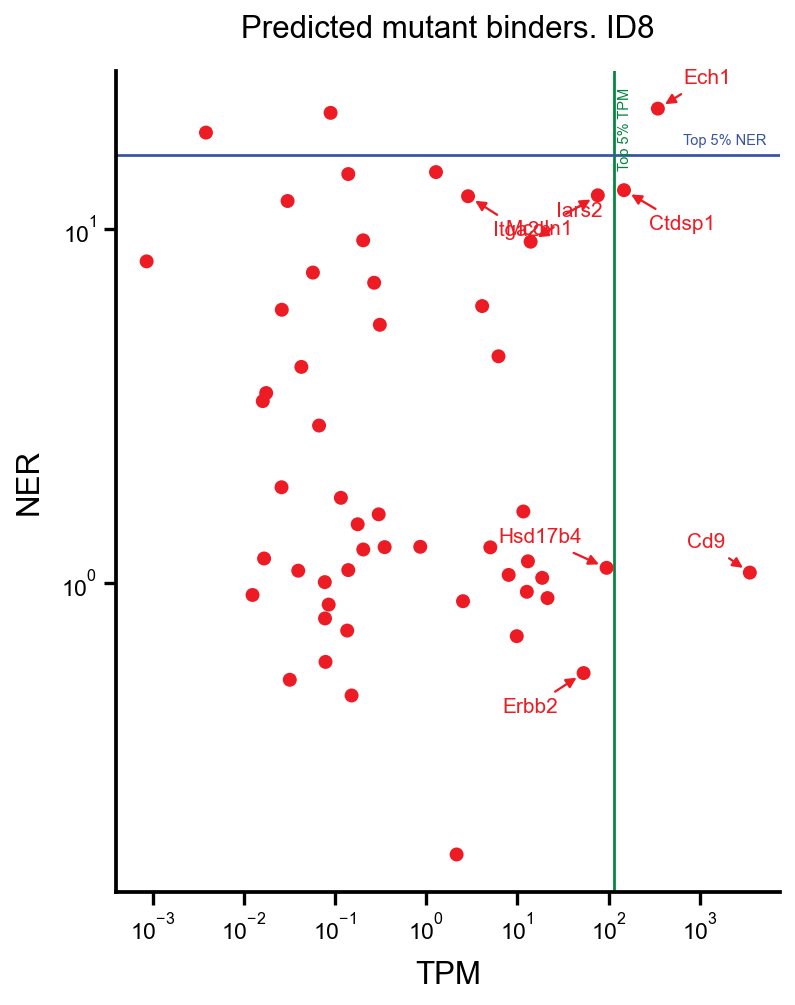

ID8
Strong binders shown: 53
Top 5% TPM threshold: 116.1
Top 5% NER threshold: 16.11
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/ID8_TPM_NER_article_style.svg


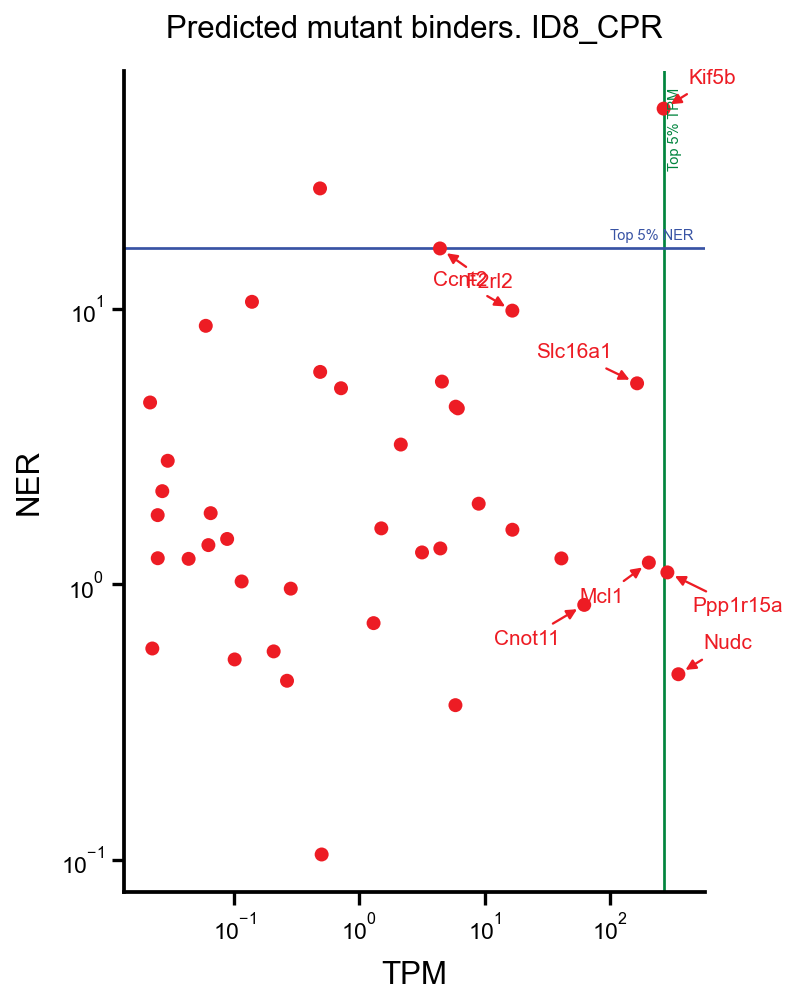

ID8_CPR
Strong binders shown: 41
Top 5% TPM threshold: 270.2
Top 5% NER threshold: 16.61
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/ID8_CPR_TPM_NER_article_style.svg


In [15]:
results = {}

for sample in ["ID8", "ID8_CPR"]:
    plot_data, thresholds = plot_article_style_tpm_ner(
        predictions_with_tpm,
        sample=sample,
        binder_cutoff=2.0,
        top_percent=5,
        label_n=8,
        output_dir=OUTPUT_DIR,
    )

    results[sample] = {
        "plot_data": plot_data,
        "thresholds": thresholds,
    }

In [22]:
best_candidates = {}

for sample in ["ID8", "ID8_CPR"]:
    plot_data = results[sample]["plot_data"]
    thresholds = results[sample]["thresholds"]

    best = (
        plot_data[
            plot_data["mean_TPM"].ge(thresholds["TPM_threshold"])
            & plot_data["NER_mean"].ge(thresholds["NER_threshold"])
        ]
        .sort_values(
            ["NER_mean", "mean_TPM"],
            ascending=[False, False],
        )
        [
            [
                "gene_name",
                "mean_TPM",
                "NER_mean",
                "WT_peptide",
                "MT_peptide",
                "WT_mean_percentile_rank",
                "MT_mean_percentile_rank",
                "length",
            ]
        ]
        .reset_index(drop=True)
    )

    best_candidates[sample] = best

    print(f"\n{sample}: {len(best)} best candidates")
    display(best)


ID8: 1 best candidates


,gene_name,mean_TPM,NER_mean,WT_peptide,MT_peptide,WT_mean_percentile_rank,MT_mean_percentile_rank,length
0,Ech1,347.631456,21.785714,SVDESLDYM,SVIESLDYM,1.728333,0.079333,9



ID8_CPR: 1 best candidates


,gene_name,mean_TPM,NER_mean,WT_peptide,MT_peptide,WT_mean_percentile_rank,MT_mean_percentile_rank,length
0,Kif5b,270.186633,53.49435,STLLFGQR,STLLFGQV,6.312333,0.118,8


In [23]:
def plot_tool_length_tpm_ner(
    df,
    sample,
    length,
    tool,
    binder_cutoff=2.0,
    top_percent=5,
    label_n=15,
    output_dir=".",
):
    data = df.loc[
        df["sample"].eq(sample)
        & df["length"].eq(length)
        & df["tool"].eq(tool)
    ].copy()

    numeric_columns = [
        "mean_TPM",
        "NER",
        "MT_percentile_rank",
    ]

    for column in numeric_columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce",
        )

    valid = (
        data["mean_TPM"].gt(0)
        & data["NER"].gt(0)
        & np.isfinite(data["mean_TPM"])
        & np.isfinite(data["NER"])
        & np.isfinite(data["MT_percentile_rank"])
    )

    data = data.loc[valid].copy()

    plot_data = data.loc[
        data["MT_percentile_rank"].le(binder_cutoff)
    ].copy()

    plot_data = plot_data.dropna(
        subset=["gene_name"]
    ).copy()

    quantile = 1 - top_percent / 100

    tpm_threshold = (
        plot_data["mean_TPM"]
        .quantile(quantile)
    )

    ner_threshold = (
        plot_data["NER"]
        .quantile(quantile)
    )

    plot_data["label_score"] = (
        np.log10(plot_data["mean_TPM"])
        + np.log10(plot_data["NER"])
    )

    label_data = (
        plot_data
        .sort_values(
            "label_score",
            ascending=False,
        )
        .head(label_n)
    )

    red = "#ED1C24"
    green = "#00843D"
    blue = "#3853A4"

    with plt.rc_context({
        "font.family": "Arial",
        "font.size": 10,
        "axes.linewidth": 1.8,
        "xtick.major.width": 1.6,
        "ytick.major.width": 1.6,
    }):
        fig, ax = plt.subplots(
            figsize=(5.4, 6.8),
            dpi=150,
        )

        ax.scatter(
            plot_data["mean_TPM"],
            plot_data["NER"],
            s=45,
            color=red,
            edgecolors="none",
            zorder=3,
        )

        ax.axvline(
            tpm_threshold,
            color=green,
            linewidth=1.3,
            zorder=2,
        )

        ax.axhline(
            ner_threshold,
            color=blue,
            linewidth=1.3,
            zorder=2,
        )

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.xaxis.set_major_locator(
            LogLocator(base=10)
        )
        ax.yaxis.set_major_locator(
            LogLocator(base=10)
        )

        ax.xaxis.set_major_formatter(
            LogFormatterMathtext()
        )
        ax.yaxis.set_major_formatter(
            LogFormatterMathtext()
        )

        ax.xaxis.set_minor_locator(
            NullLocator()
        )
        ax.yaxis.set_minor_locator(
            NullLocator()
        )

        ax.set_title(
            f"Predicted mutant binders. {sample}\n"
            f"{tool}, {length} aa",
            fontsize=14,
            pad=16,
        )

        ax.set_xlabel(
            "mean TPM",
            fontsize=14,
            labelpad=8,
        )

        ax.set_ylabel(
            f"NER ({tool})",
            fontsize=14,
            labelpad=8,
        )

        ax.text(
            tpm_threshold * 1.08,
            0.98,
            f"Top {top_percent}% TPM",
            color=green,
            fontsize=7,
            rotation=90,
            va="top",
            ha="left",
            transform=ax.get_xaxis_transform(),
        )

        ax.text(
            0.98,
            ner_threshold * 1.05,
            f"Top {top_percent}% NER",
            color=blue,
            fontsize=7,
            va="bottom",
            ha="right",
            transform=ax.get_yaxis_transform(),
        )

        offsets = [
            (12, 10),
            (-12, 10),
            (12, -12),
            (-12, -12),
        ]

        for position, (_, row) in enumerate(
            label_data.iterrows()
        ):
            offset = offsets[
                position % len(offsets)
            ]

            ax.annotate(
                str(row["gene_name"]),
                xy=(
                    row["mean_TPM"],
                    row["NER"],
                ),
                xytext=offset,
                textcoords="offset points",
                color=red,
                fontsize=10,
                ha=(
                    "left"
                    if offset[0] > 0
                    else "right"
                ),
                va=(
                    "bottom"
                    if offset[1] > 0
                    else "top"
                ),
                arrowprops={
                    "arrowstyle": "-|>",
                    "color": red,
                    "linewidth": 1.1,
                    "mutation_scale": 10,
                    "shrinkA": 2,
                    "shrinkB": 4,
                },
                annotation_clip=True,
                zorder=4,
            )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=6,
            width=1.6,
            labelsize=11,
        )

        ax.grid(False)
        plt.tight_layout()

        output_dir = Path(output_dir)
        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        output_path = output_dir / (
            f"{sample}_length-{length}_"
            f"{tool}_TPM_NER.svg"
        )

        fig.savefig(
            output_path,
            format="svg",
            bbox_inches="tight",
            transparent=False,
        )

        plt.show()

    print(
        f"{sample} | {length} aa | {tool}"
    )
    print(
        f"Strong binders shown: "
        f"{len(plot_data):,}"
    )
    print(
        f"Top {top_percent}% TPM threshold: "
        f"{tpm_threshold:.4g}"
    )
    print(
        f"Top {top_percent}% NER threshold: "
        f"{ner_threshold:.4g}"
    )
    print(f"Saved: {output_path}")

    return plot_data, {
        "TPM_threshold": tpm_threshold,
        "NER_threshold": ner_threshold,
        "n_strong_binders": len(plot_data),
        "output_path": output_path,
    }

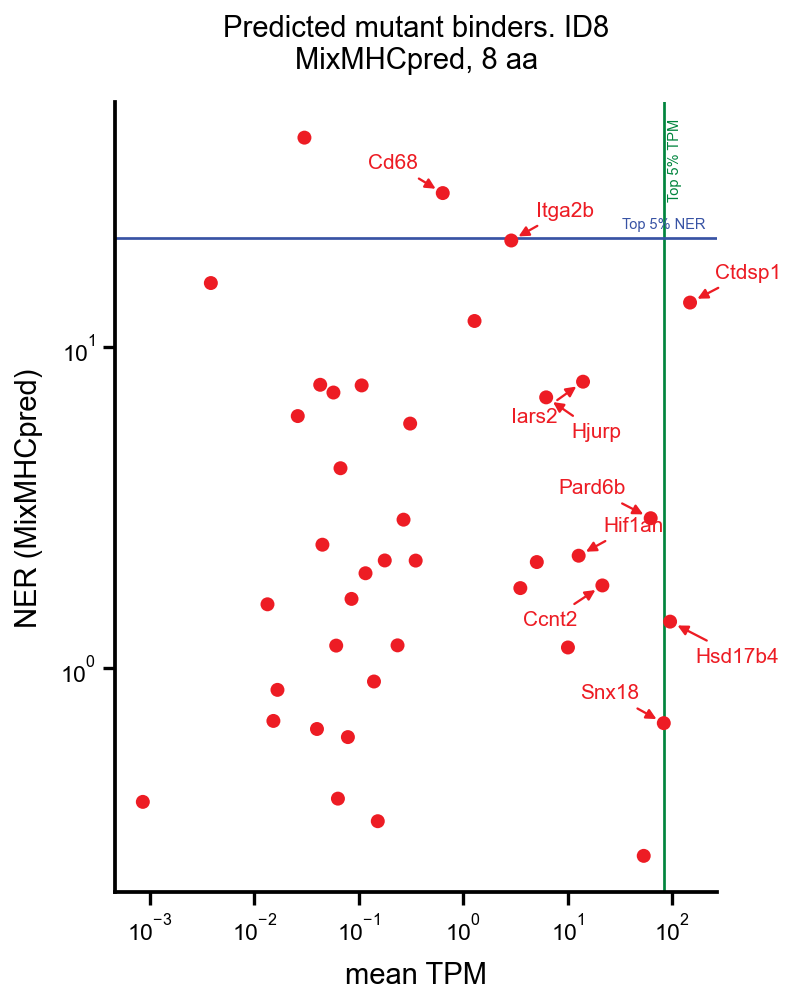

ID8 | 8 aa | MixMHCpred
Strong binders shown: 40
Top 5% TPM threshold: 83.42
Top 5% NER threshold: 21.94
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-8_MixMHCpred_TPM_NER.svg


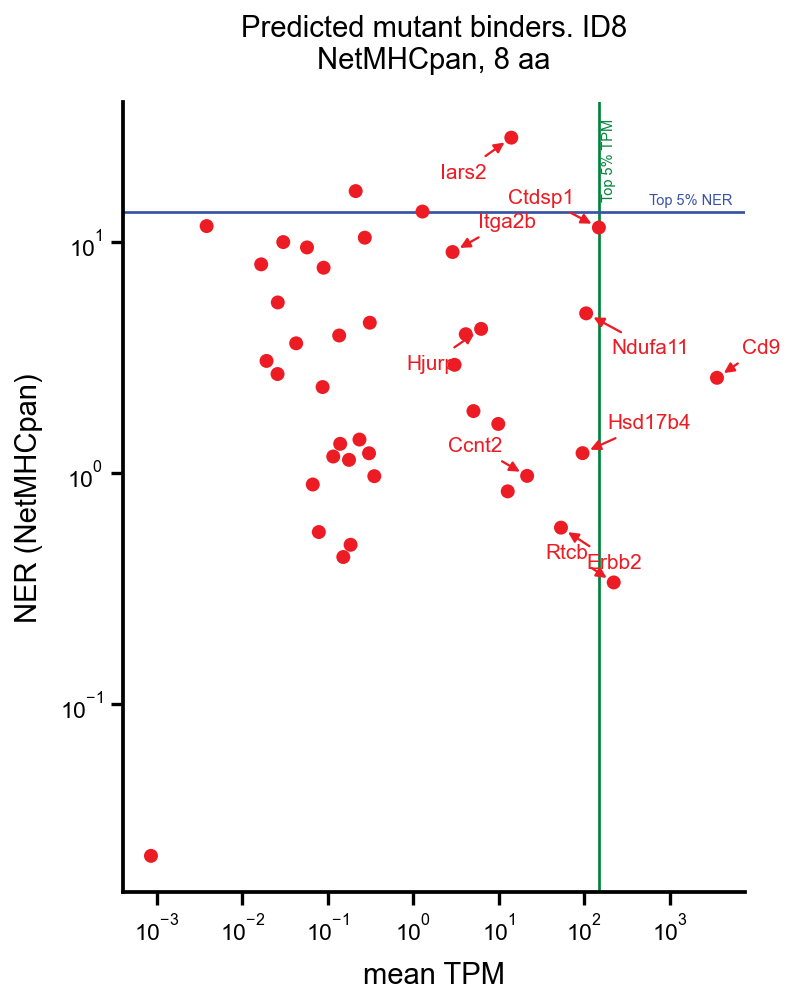

ID8 | 8 aa | NetMHCpan
Strong binders shown: 41
Top 5% TPM threshold: 147.7
Top 5% NER threshold: 13.55
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-8_NetMHCpan_TPM_NER.svg


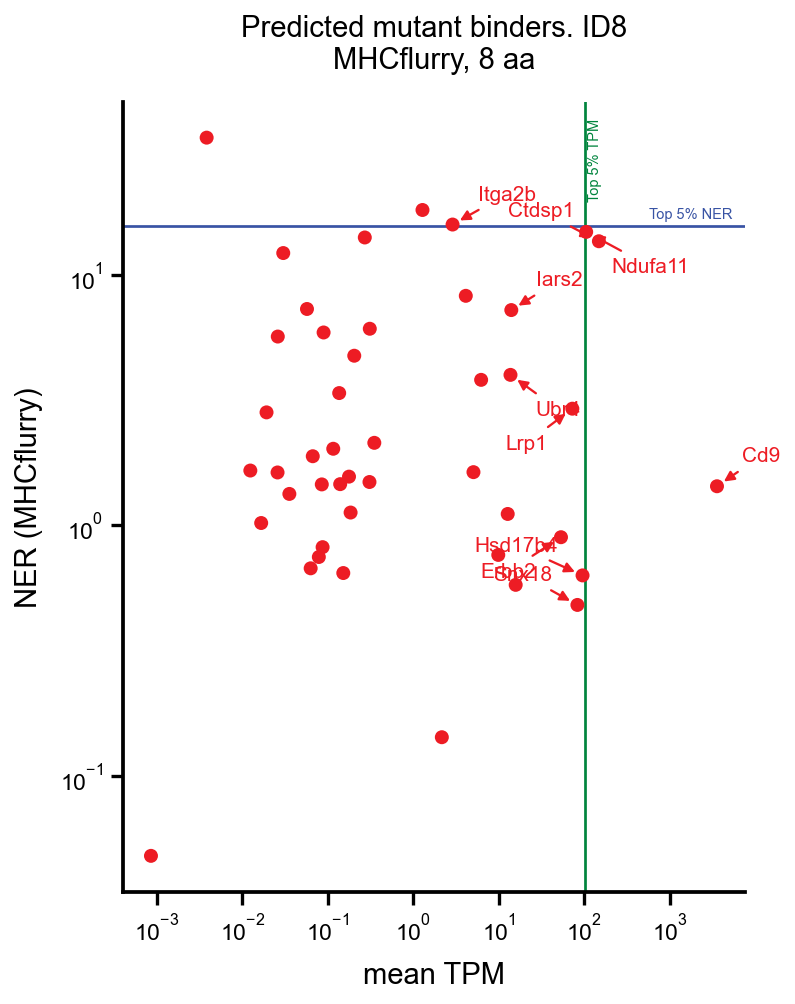

ID8 | 8 aa | MHCflurry
Strong binders shown: 45
Top 5% TPM threshold: 102.9
Top 5% NER threshold: 15.69
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-8_MHCflurry_TPM_NER.svg


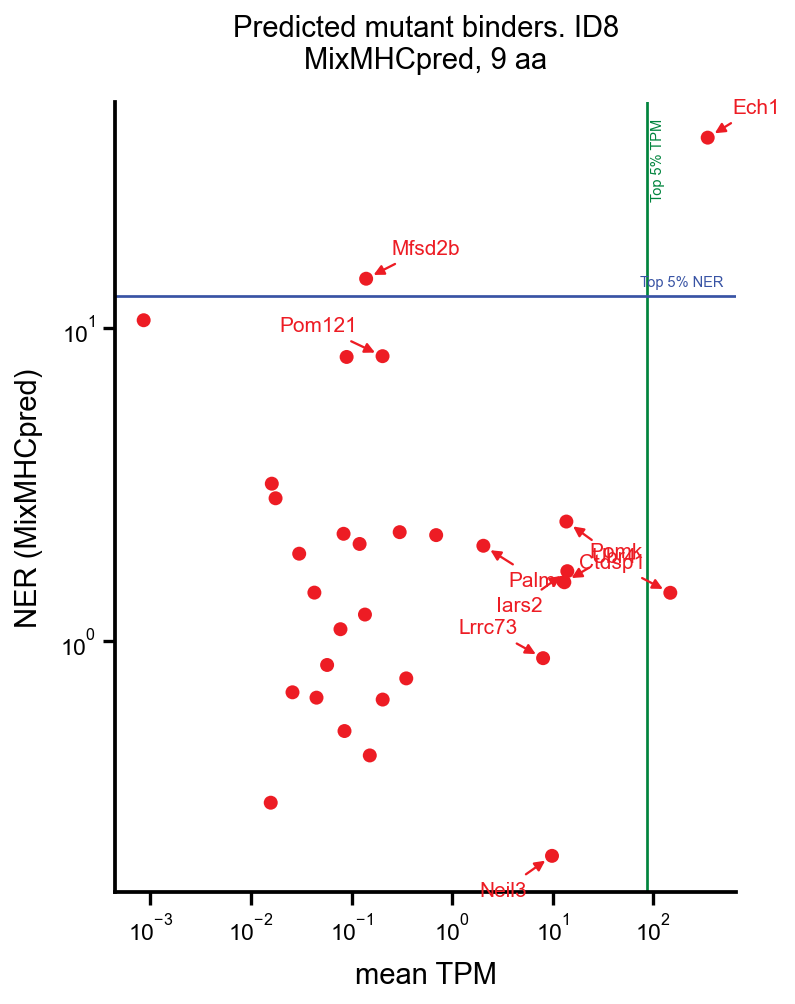

ID8 | 9 aa | MixMHCpred
Strong binders shown: 30
Top 5% TPM threshold: 87.51
Top 5% NER threshold: 12.69
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-9_MixMHCpred_TPM_NER.svg


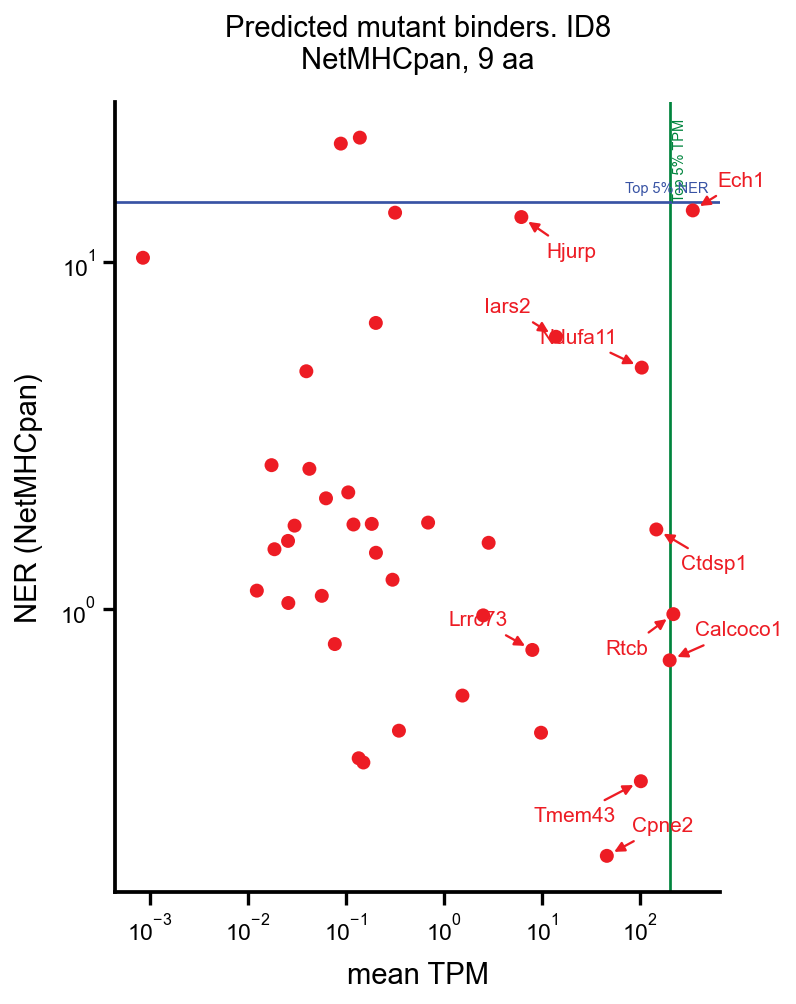

ID8 | 9 aa | NetMHCpan
Strong binders shown: 39
Top 5% TPM threshold: 203.8
Top 5% NER threshold: 14.9
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-9_NetMHCpan_TPM_NER.svg


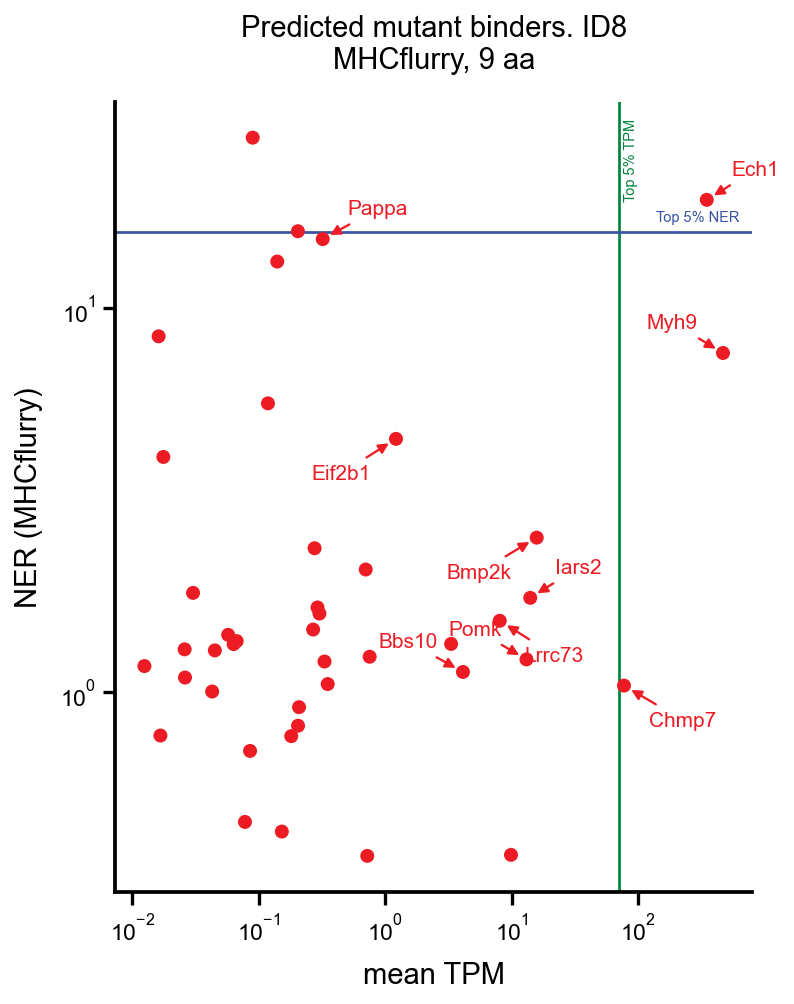

ID8 | 9 aa | MHCflurry
Strong binders shown: 43
Top 5% TPM threshold: 70.92
Top 5% NER threshold: 15.79
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-9_MHCflurry_TPM_NER.svg


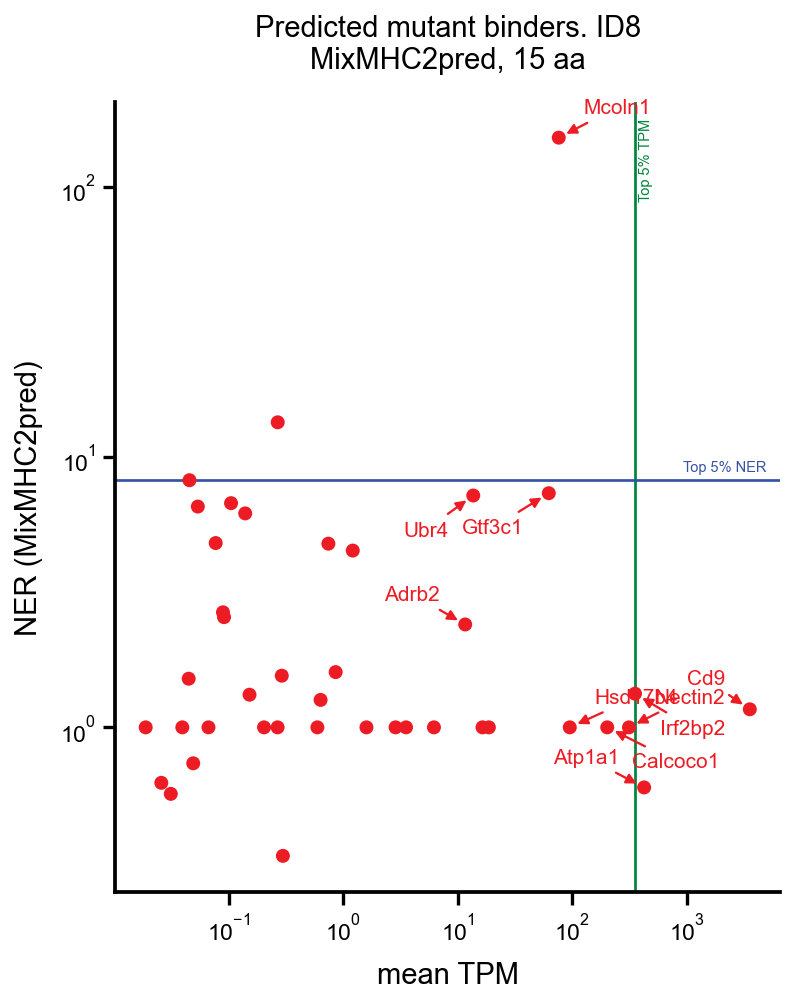

ID8 | 15 aa | MixMHC2pred
Strong binders shown: 41
Top 5% TPM threshold: 353
Top 5% NER threshold: 8.216
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-15_MixMHC2pred_TPM_NER.svg


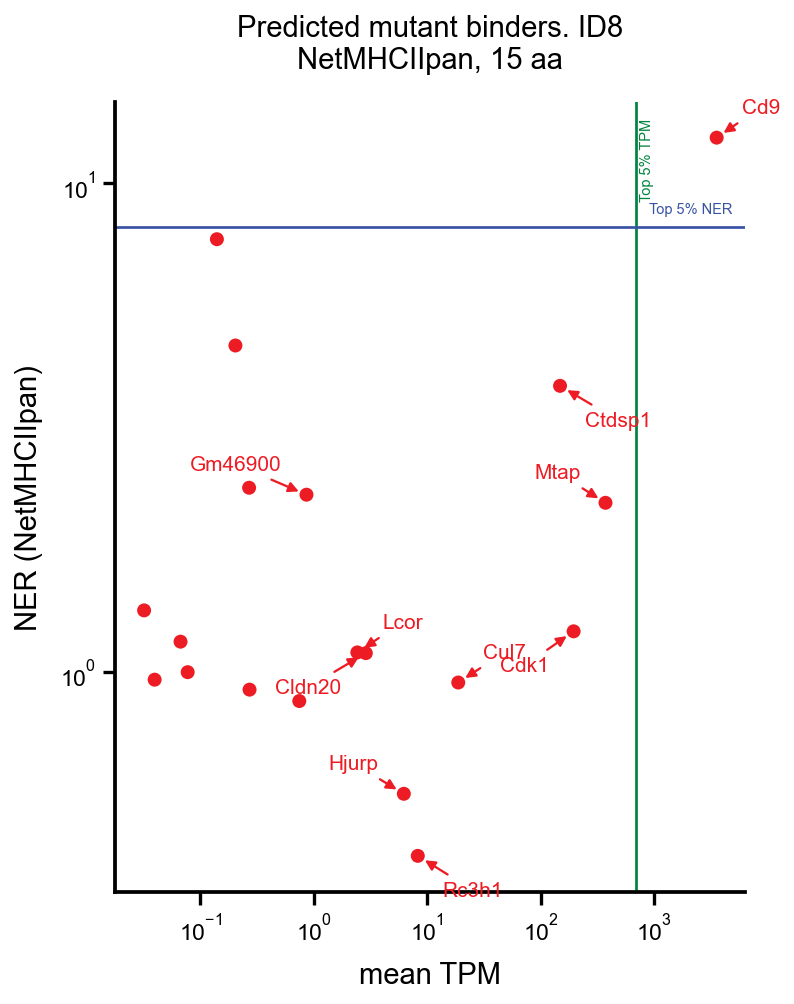

ID8 | 15 aa | NetMHCIIpan
Strong binders shown: 19
Top 5% TPM threshold: 689
Top 5% NER threshold: 8.162
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-15_NetMHCIIpan_TPM_NER.svg


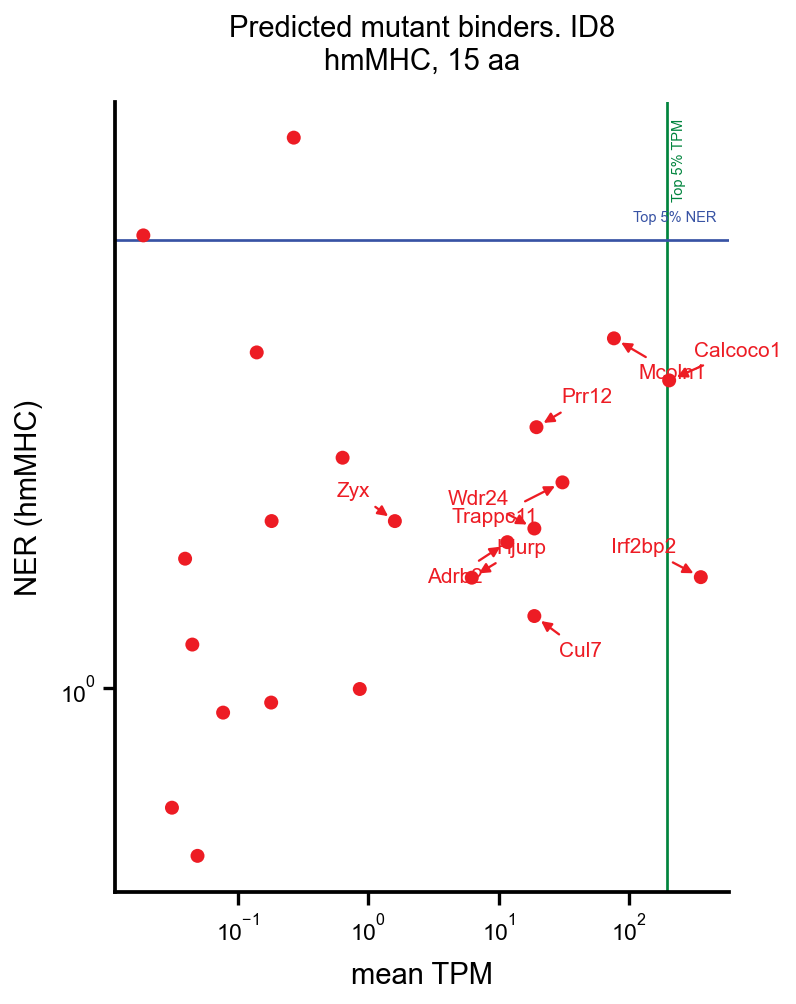

ID8 | 15 aa | hmMHC
Strong binders shown: 22
Top 5% TPM threshold: 195.7
Top 5% NER threshold: 4.162
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_length-15_hmMHC_TPM_NER.svg


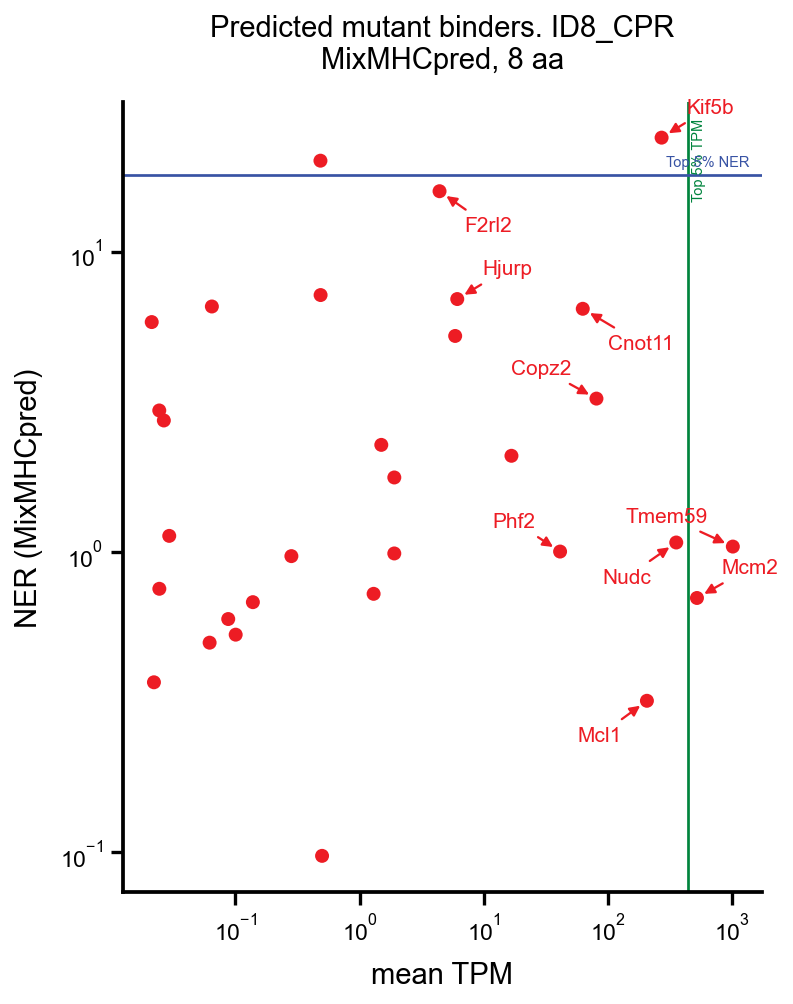

ID8_CPR | 8 aa | MixMHCpred
Strong binders shown: 31
Top 5% TPM threshold: 437.5
Top 5% NER threshold: 18.06
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-8_MixMHCpred_TPM_NER.svg


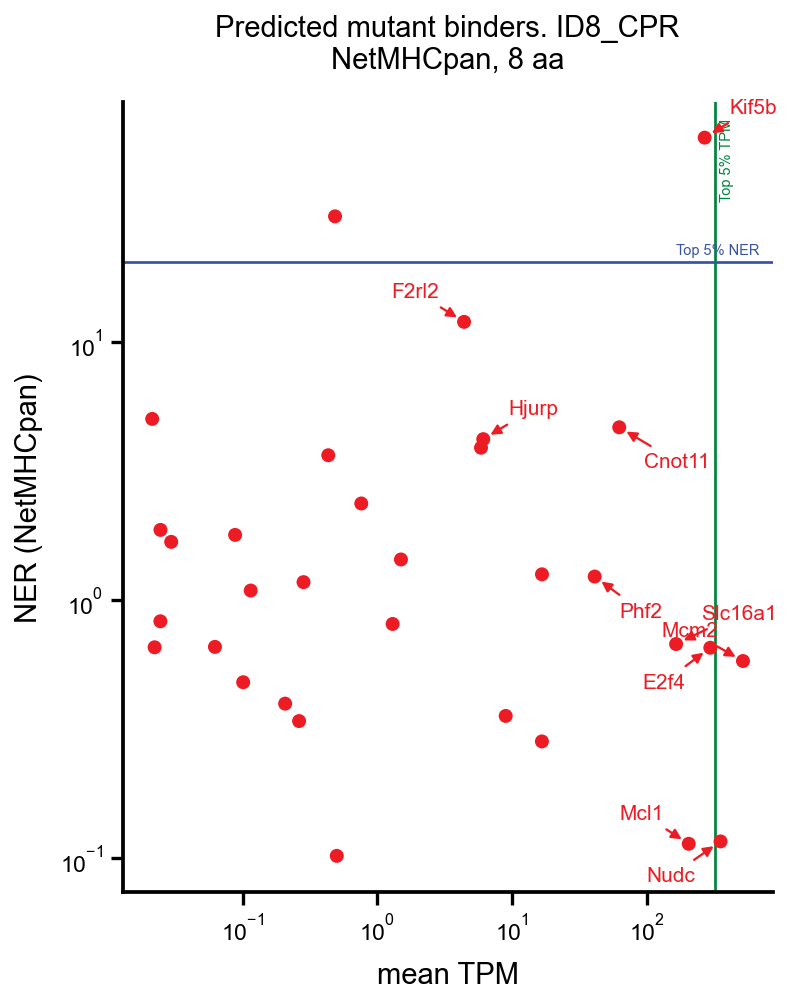

ID8_CPR | 8 aa | NetMHCpan
Strong binders shown: 32
Top 5% TPM threshold: 323.2
Top 5% NER threshold: 20.46
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-8_NetMHCpan_TPM_NER.svg


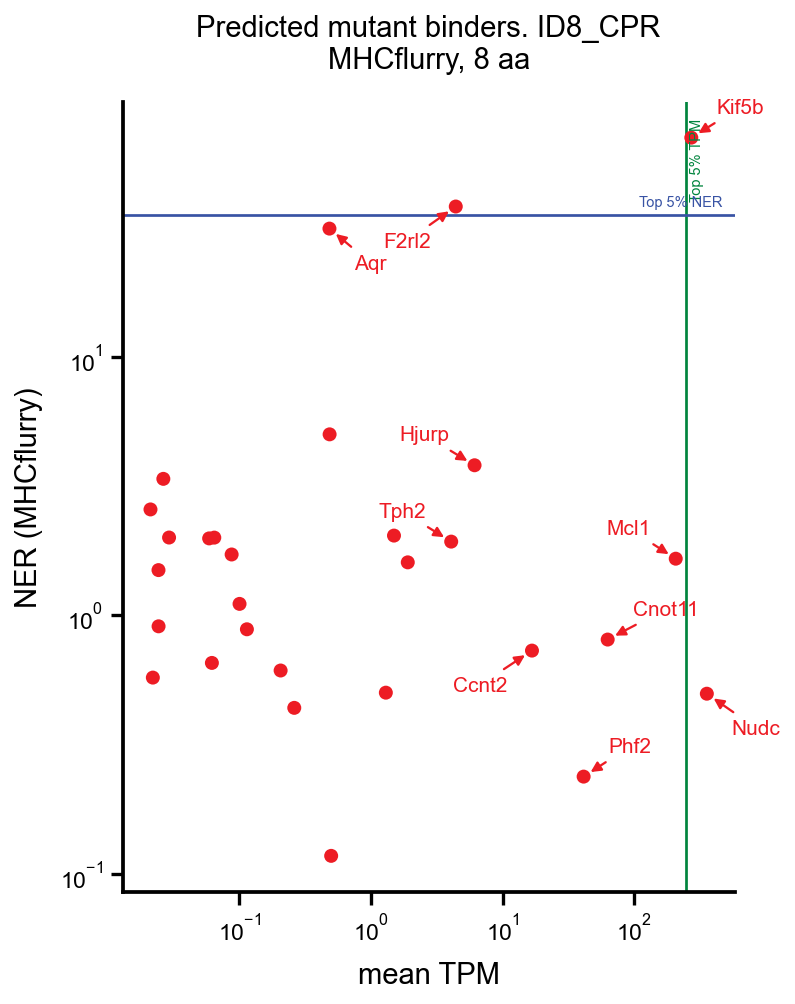

ID8_CPR | 8 aa | MHCflurry
Strong binders shown: 29
Top 5% TPM threshold: 244.4
Top 5% NER threshold: 35.5
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-8_MHCflurry_TPM_NER.svg


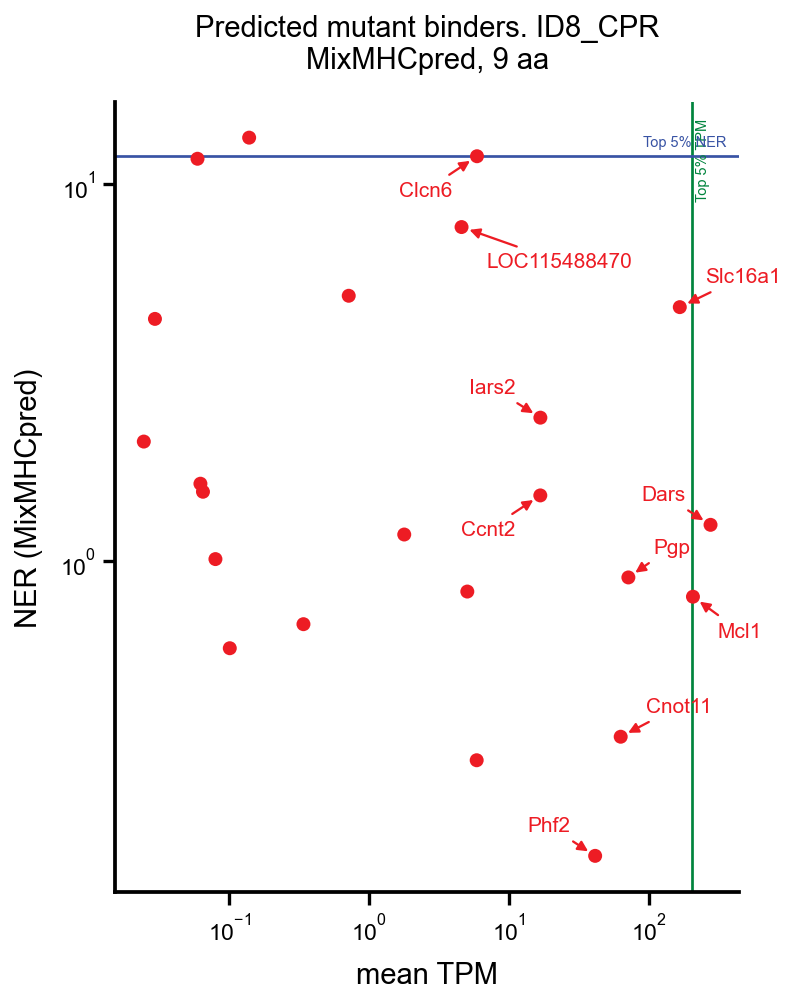

ID8_CPR | 9 aa | MixMHCpred
Strong binders shown: 23
Top 5% TPM threshold: 201.8
Top 5% NER threshold: 11.84
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-9_MixMHCpred_TPM_NER.svg


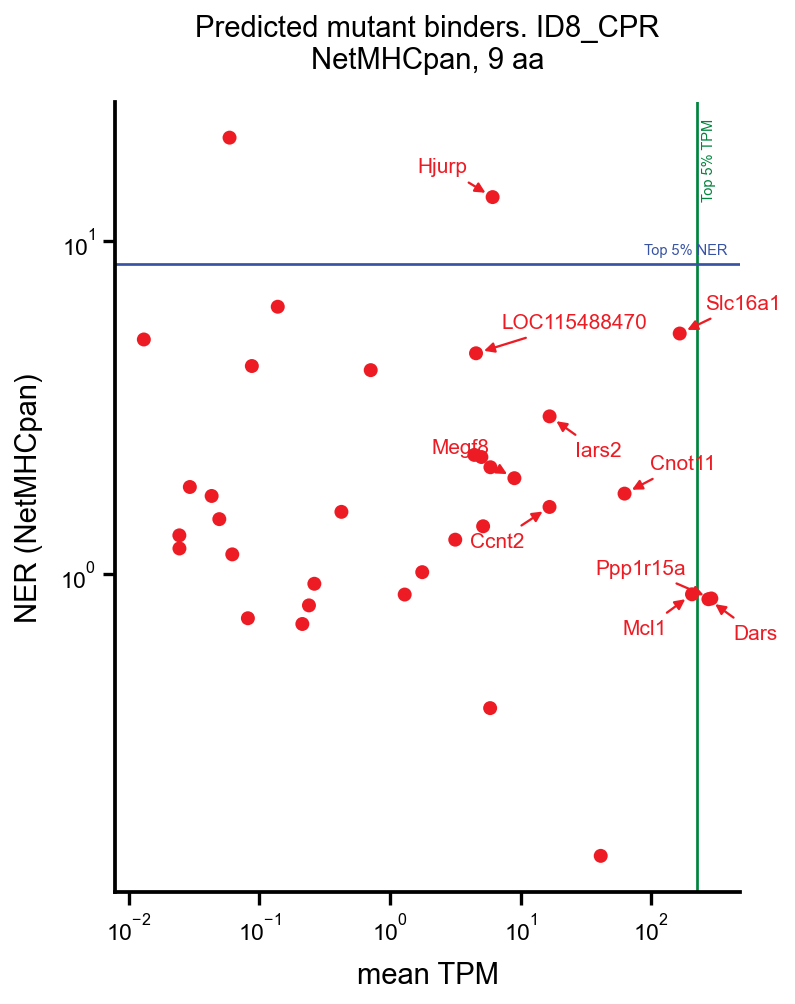

ID8_CPR | 9 aa | NetMHCpan
Strong binders shown: 35
Top 5% TPM threshold: 226.5
Top 5% NER threshold: 8.481
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-9_NetMHCpan_TPM_NER.svg


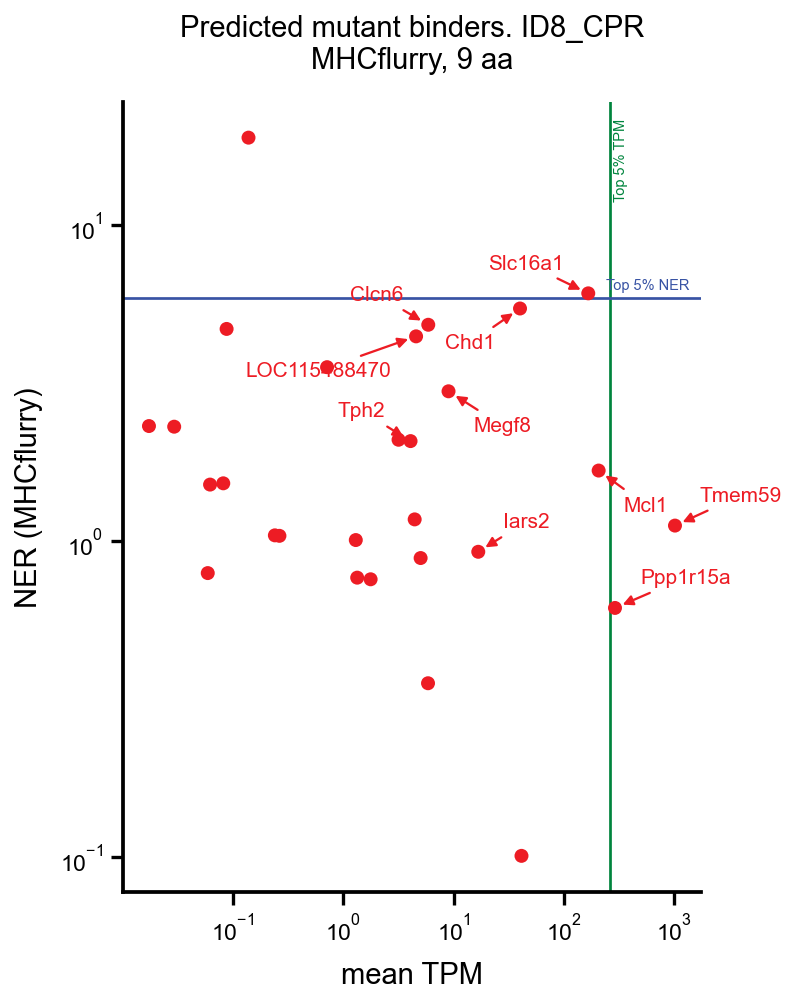

ID8_CPR | 9 aa | MHCflurry
Strong binders shown: 28
Top 5% TPM threshold: 260.2
Top 5% NER threshold: 5.842
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-9_MHCflurry_TPM_NER.svg


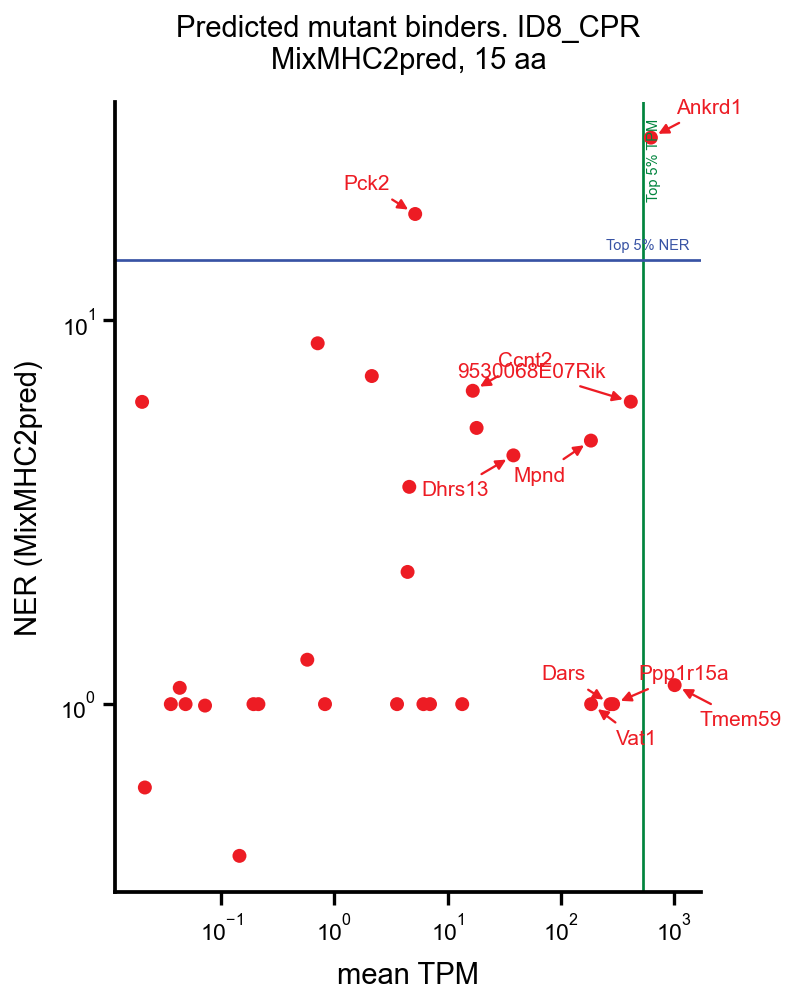

ID8_CPR | 15 aa | MixMHC2pred
Strong binders shown: 30
Top 5% TPM threshold: 530
Top 5% NER threshold: 14.33
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-15_MixMHC2pred_TPM_NER.svg


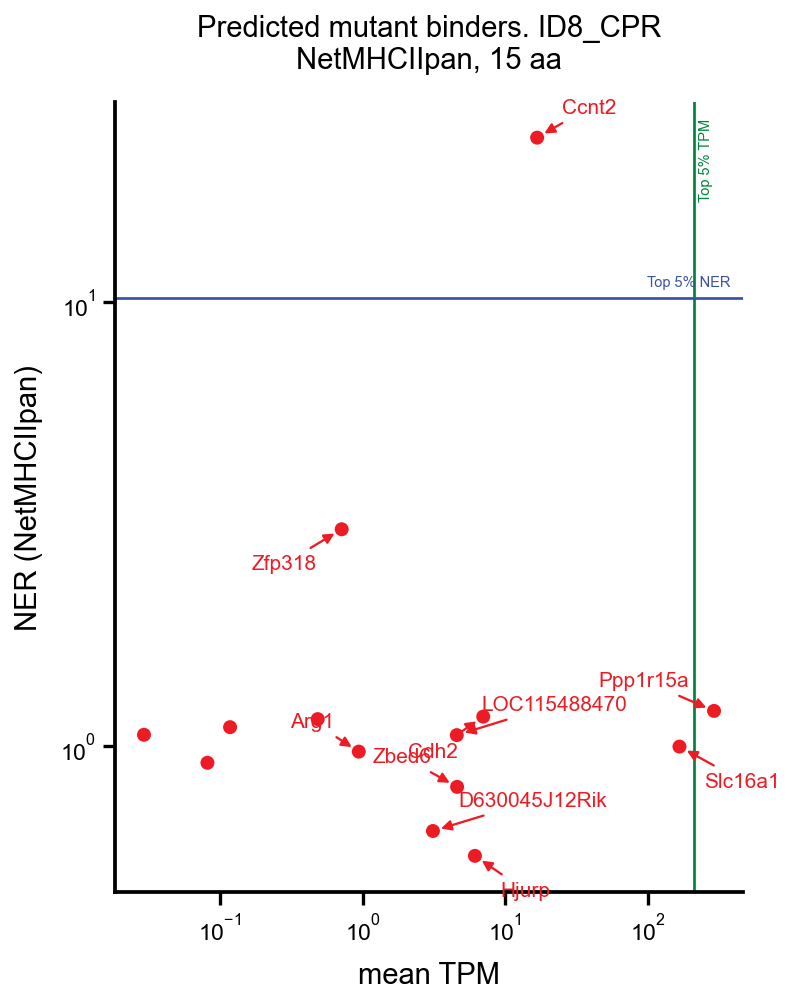

ID8_CPR | 15 aa | NetMHCIIpan
Strong binders shown: 14
Top 5% TPM threshold: 209
Top 5% NER threshold: 10.19
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-15_NetMHCIIpan_TPM_NER.svg


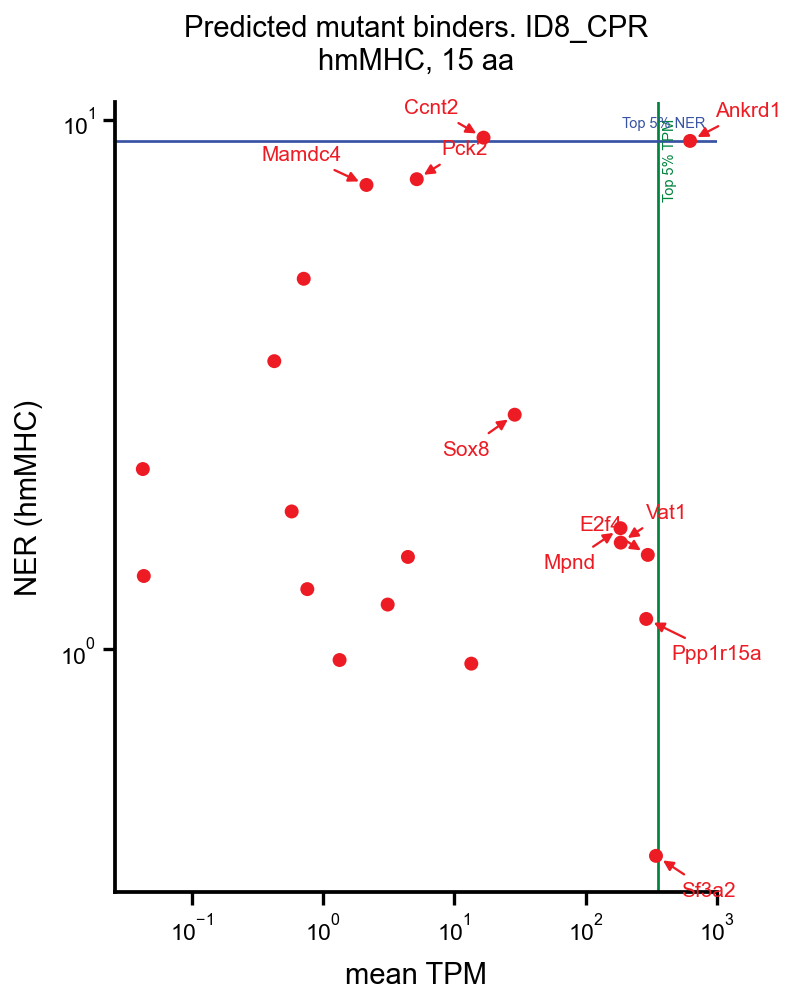

ID8_CPR | 15 aa | hmMHC
Strong binders shown: 20
Top 5% TPM threshold: 357.5
Top 5% NER threshold: 9.142
Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/per_tool_and_length/ID8_CPR_length-15_hmMHC_TPM_NER.svg


,sample,length,tool,strong_binders_shown,TPM_threshold,NER_threshold
0,ID8,8,MixMHCpred,40,83.420225,21.943332
1,ID8,8,NetMHCpan,41,147.669454,13.551674
2,ID8,8,MHCflurry,45,102.891673,15.688315
3,ID8,9,MixMHCpred,30,87.507209,12.686833
4,ID8,9,NetMHCpan,39,203.757094,14.900000
5,ID8,9,MHCflurry,43,70.919887,15.789458
6,ID8,15,MixMHC2pred,41,352.997110,8.215586
7,ID8,15,NetMHCIIpan,19,688.959566,8.162206
8,ID8,15,hmMHC,22,195.652003,4.162000
9,ID8_CPR,8,MixMHCpred,31,437.461214,18.063357


In [24]:
per_tool_results = {}
summary_rows = []

output_dir = (
    OUTPUT_DIR
    / "per_tool_and_length"
)

for sample in SAMPLES:
    for length, tool_columns in (
        TOOL_PERCENTILE_COLUMNS.items()
    ):
        for tool in tool_columns:

            key = (
                sample,
                length,
                tool,
            )

            try:
                plot_data, thresholds = (
                    plot_tool_length_tpm_ner(
                        per_tool_predictions,
                        sample=sample,
                        length=length,
                        tool=tool,
                        binder_cutoff=2.0,
                        top_percent=5,
                        label_n=10,
                        output_dir=output_dir,
                    )
                )

            except ValueError as error:
                print(
                    f"Skipped {key}: {error}"
                )
                continue

            per_tool_results[key] = {
                "plot_data": plot_data,
                "thresholds": thresholds,
            }

            summary_rows.append({
                "sample": sample,
                "length": length,
                "tool": tool,
                "strong_binders_shown": (
                    thresholds[
                        "n_strong_binders"
                    ]
                ),
                "TPM_threshold": (
                    thresholds[
                        "TPM_threshold"
                    ]
                ),
                "NER_threshold": (
                    thresholds[
                        "NER_threshold"
                    ]
                ),
            })


per_tool_summary = pd.DataFrame(
    summary_rows
)

display(per_tool_summary)

In [25]:
best_candidates_per_tool = {}

for sample in SAMPLES:
    sample_candidates = []

    for length, tool_columns in TOOL_PERCENTILE_COLUMNS.items():
        for tool in tool_columns:

            key = (sample, length, tool)

            # Для этой комбинации вообще не был построен анализ
            if key not in per_tool_results:
                continue

            plot_data = (
                per_tool_results[key]["plot_data"]
                .copy()
            )

            thresholds = (
                per_tool_results[key]["thresholds"]
            )

            candidates = plot_data.loc[
                plot_data["mean_TPM"].ge(
                    thresholds["TPM_threshold"]
                )
                & plot_data["NER"].ge(
                    thresholds["NER_threshold"]
                )
            ].copy()


            best = (
                candidates
                .sort_values(
                    ["NER", "mean_TPM"],
                    ascending=[False, False],
                )
                .copy()
            )

            best["sample"] = sample
            best["length"] = length
            best["tool"] = tool

            sample_candidates.append(best)

    if sample_candidates:
        sample_table = (
            pd.concat(
                sample_candidates,
                ignore_index=True,
            )
            [
                [
                    "tool",
                    "length",
                    "gene_name",
                    "mean_TPM",
                    "NER",
                    "WT_peptide",
                    "MT_peptide",
                    "WT_percentile_rank",
                    "MT_percentile_rank",
                ]
            ]
            .rename(
                columns={
                    "NER": "NER_tool",
                    "WT_percentile_rank":
                        "WT_tool_percentile_rank",
                    "MT_percentile_rank":
                        "MT_tool_percentile_rank",
                }
            )
            .sort_values(
                ["length", "tool"]
            )
            .reset_index(drop=True)
        )

    else:
        sample_table = pd.DataFrame()

    best_candidates_per_tool[sample] = sample_table

    print(
        f"\n{sample}: "
        f"{len(sample_table)} best candidates"
    )

    display(sample_table)

ID8 | 8 aa | MixMHCpred: кандидатов нет
ID8 | 8 aa | NetMHCpan: кандидатов нет
ID8 | 8 aa | MHCflurry: кандидатов нет
ID8 | 9 aa | NetMHCpan: кандидатов нет
ID8 | 15 aa | MixMHC2pred: кандидатов нет
ID8 | 15 aa | hmMHC: кандидатов нет

ID8: 3 best candidates


,tool,length,gene_name,mean_TPM,NER_tool,WT_peptide,MT_peptide,WT_tool_percentile_rank,MT_tool_percentile_rank
0,MHCflurry,9,Ech1,347.631456,19.155963,SVDESLDYM,SVIESLDYM,2.088,0.109
1,MixMHCpred,9,Ech1,347.631456,40.708333,SVDESLDYM,SVIESLDYM,1.954,0.048
2,NetMHCIIpan,15,Cd9,3546.111709,12.408102,GFNFIFWLAGIAVLA,GFNFIFWPAGIAVLA,16.54,1.333


ID8_CPR | 8 aa | MixMHCpred: кандидатов нет
ID8_CPR | 8 aa | NetMHCpan: кандидатов нет
ID8_CPR | 9 aa | MixMHCpred: кандидатов нет
ID8_CPR | 9 aa | NetMHCpan: кандидатов нет
ID8_CPR | 9 aa | MHCflurry: кандидатов нет
ID8_CPR | 15 aa | NetMHCIIpan: кандидатов нет
ID8_CPR | 15 aa | hmMHC: кандидатов нет

ID8_CPR: 2 best candidates


,tool,length,gene_name,mean_TPM,NER_tool,WT_peptide,MT_peptide,WT_tool_percentile_rank,MT_tool_percentile_rank
0,MHCflurry,8,Kif5b,270.186633,70.640000,STLLFGQR,STLLFGQV,7.064,0.100
1,MixMHC2pred,15,Ankrd1,624.235893,29.933775,VDVPRFLKAALENKL,VDVPRFPKAALENKL,27.12,0.906


In [26]:
def build_and_save_best_candidates_per_tool(
    per_tool_results,
    samples,
    tool_percentile_columns,
    output_path,
    show_tables=True,
):
    output_columns = [
        "tool",
        "length",
        "gene_name",
        "mean_TPM",
        "NER_tool",
        "WT_peptide",
        "MT_peptide",
        "WT_tool_percentile_rank",
        "MT_tool_percentile_rank",
    ]

    best_candidates_per_tool = {}

    for sample in samples:
        sample_candidates = []

        for length, tool_columns in tool_percentile_columns.items():
            for tool in tool_columns:

                key = (sample, length, tool)

                plot_data = (
                    per_tool_results[key]["plot_data"]
                    .copy()
                )

                thresholds = (
                    per_tool_results[key]["thresholds"]
                )

                candidates = plot_data.loc[
                    plot_data["mean_TPM"].ge(
                        thresholds["TPM_threshold"]
                    )
                    & plot_data["NER"].ge(
                        thresholds["NER_threshold"]
                    )
                ].copy()


                candidates["sample"] = sample
                candidates["length"] = length
                candidates["tool"] = tool

                sample_candidates.append(candidates)

        if sample_candidates:
            sample_table = (
                pd.concat(
                    sample_candidates,
                    ignore_index=True,
                )
                [
                    [
                        "tool",
                        "length",
                        "gene_name",
                        "mean_TPM",
                        "NER",
                        "WT_peptide",
                        "MT_peptide",
                        "WT_percentile_rank",
                        "MT_percentile_rank",
                    ]
                ]
                .rename(
                    columns={
                        "NER": "NER_tool",
                        "WT_percentile_rank":
                            "WT_tool_percentile_rank",
                        "MT_percentile_rank":
                            "MT_tool_percentile_rank",
                    }
                )
                .sort_values(
                    [
                        "length",
                        "tool",
                        "NER_tool",
                        "mean_TPM",
                    ],
                    ascending=[
                        True,
                        True,
                        False,
                        False,
                    ],
                )
                .reset_index(drop=True)
            )

        else:
            sample_table = pd.DataFrame(
                columns=output_columns
            )

        best_candidates_per_tool[sample] = sample_table

        print(
            f"\n{sample}: "
            f"{len(sample_table)} best candidates"
        )

        if show_tables:
            display(sample_table)

    combined_tables = []

    for sample, sample_table in (
        best_candidates_per_tool.items()
    ):
        table_to_combine = sample_table.copy()
        table_to_combine.insert(0, "sample", sample)
        combined_tables.append(table_to_combine)

    combined_table = pd.concat(
        combined_tables,
        ignore_index=True,
    )


    output_path = Path(output_path)
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    with pd.ExcelWriter(
        output_path,
        engine="openpyxl",
    ) as writer:

        combined_table.to_excel(
            writer,
            sheet_name="All_candidates",
            index=False,
        )

        for sample, sample_table in (
            best_candidates_per_tool.items()
        ):
            sample_table.to_excel(
                writer,
                sheet_name=str(sample)[:31],
                index=False,
            )

    print(f"\nSaved: {output_path}")

    return best_candidates_per_tool

In [27]:
best_candidates_per_tool = (
    build_and_save_best_candidates_per_tool(
        per_tool_results=per_tool_results,
        samples=SAMPLES,
        tool_percentile_columns=TOOL_PERCENTILE_COLUMNS,
        output_path=(
            OUTPUT_DIR
            / "best_candidates_per_tool.xlsx"
        ),
    )
)

ID8 | 8 aa | MixMHCpred: кандидатов нет
ID8 | 8 aa | NetMHCpan: кандидатов нет
ID8 | 8 aa | MHCflurry: кандидатов нет
ID8 | 9 aa | NetMHCpan: кандидатов нет
ID8 | 15 aa | MixMHC2pred: кандидатов нет
ID8 | 15 aa | hmMHC: кандидатов нет

ID8: 3 best candidates


,tool,length,gene_name,mean_TPM,NER_tool,WT_peptide,MT_peptide,WT_tool_percentile_rank,MT_tool_percentile_rank
0,MHCflurry,9,Ech1,347.631456,19.155963,SVDESLDYM,SVIESLDYM,2.088,0.109
1,MixMHCpred,9,Ech1,347.631456,40.708333,SVDESLDYM,SVIESLDYM,1.954,0.048
2,NetMHCIIpan,15,Cd9,3546.111709,12.408102,GFNFIFWLAGIAVLA,GFNFIFWPAGIAVLA,16.54,1.333


ID8_CPR | 8 aa | MixMHCpred: кандидатов нет
ID8_CPR | 8 aa | NetMHCpan: кандидатов нет
ID8_CPR | 9 aa | MixMHCpred: кандидатов нет
ID8_CPR | 9 aa | NetMHCpan: кандидатов нет
ID8_CPR | 9 aa | MHCflurry: кандидатов нет
ID8_CPR | 15 aa | NetMHCIIpan: кандидатов нет
ID8_CPR | 15 aa | hmMHC: кандидатов нет

ID8_CPR: 2 best candidates


,tool,length,gene_name,mean_TPM,NER_tool,WT_peptide,MT_peptide,WT_tool_percentile_rank,MT_tool_percentile_rank
0,MHCflurry,8,Kif5b,270.186633,70.640000,STLLFGQR,STLLFGQV,7.064,0.100
1,MixMHC2pred,15,Ankrd1,624.235893,29.933775,VDVPRFLKAALENKL,VDVPRFPKAALENKL,27.12,0.906



Saved: ~/Hussein/predictions/final_tables/wt_mt_analysis/best_candidates_per_tool.xlsx
